# Fine-Tuning Qwen3.5-0.8B for Text-to-SQL with LoRA: Tuning, Robustness, Generalisation and Scale

**Midterm Project** · Advanced Deep Learning Models

**Abstract.** We fine-tune Qwen3.5-0.8B with LoRA on 2,000 text-to-SQL examples and study it from five angles:
(1) a hyperparameter study (LoRA rank, learning rate, epochs, target modules, alpha) with selection on a separate tuning set;
(2) robustness across 3 random seeds;
(3) comparison with zero-shot and 3-shot prompting baselines;
(4) cross-dataset generalisation between `b-mc2/sql-create-context` (A) and `gretelai/synthetic_text_to_sql` (B), including training on A+B;
(5) model scaling (0.8B vs 2B vs 4B) and a training-set-size ablation.
We report Execution Accuracy, Exact Match, Valid-SQL rate, Token F1 and format compliance with 95% bootstrap CIs and McNemar significance tests.

### Contents

1. Setup, configuration, run cache
2. Datasets A and B, splits
3. Exploratory data analysis (both datasets)
4. Evaluation metrics + sanity checks
5. Model, generation and training functions
6. **Stage 1 — Hyperparameter study** (understanding how different hyperparameters affect performance and why we selected the final configuration)
7. **Stage 2 — Main comparison:** zero-shot vs 3-shot vs default LoRA vs tuned LoRA (repeated with 3 random seeds to check consistency)
8. Where fine-tuning helps: breakdowns and error analysis
9. **Stage 3 — Cross-dataset generalisation** (training and evaluating across A, B, and A+B to understand how well the model handles unfamiliar data)
10. **Stage 4 — Model scaling** (comparing 0.8B and 2B models, with an optional 4B model using 4-bit quantization)
11. **Stage 5 — Training-set-size ablation** (examining how model performance changes when we increase or decrease the amount of training data)
12. Results & Discussion (automatically summarizing and interpreting the experimental results)
13. Limitations, future work, conclusion
14. Saved models: reload and use
15. Saved artefacts and compute budget

## 1. Setup, configuration and run cache

In [ ]:
!pip install -q --upgrade unsloth unsloth_zoo
!nvidia-smi --query-gpu=name,memory.total --format=csv

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.8/79.8 kB 611.3 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.4/29.4 MB 58.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 64.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 42.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.1/135.1 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 75.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 38.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 77.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 96.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.9/216.9 kB 10.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently 

In [ ]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["WANDB_DISABLED"] = "true"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import torch
if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU visible to PyTorch. On Kaggle: right panel > Session options > Accelerator > GPU T4 x2 "
        "(not P100), then Run All again. Greyed out? Verify your phone number in Kaggle settings or check "
        f"your weekly GPU quota. (torch {torch.__version__}, CUDA build {torch.version.cuda})")
print(f"GPU OK: {torch.cuda.get_device_name(0)} | torch {torch.__version__} | CUDA {torch.version.cuda}")

from unsloth import FastLanguageModel, is_bfloat16_supported
from unsloth.chat_templates import train_on_responses_only
import re, json, sqlite3, random, time, math, gc, zlib, collections, platform, glob, shutil
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown
from tqdm.auto import tqdm
from datasets import load_dataset, Dataset
from trl import SFTTrainer, SFTConfig
from scipy.stats import binomtest, chi2_contingency

GPU OK: Tesla T4 | torch 2.11.0+cu128 | CUDA 12.8
🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!


In [ ]:
QUICK_RUN = False
RUN_TUNING        = True    # Stage 1: hyperparameter study on the tuning set
RUN_FEWSHOT       = True    # Stage 2: 3-shot prompting baseline
RUN_DEFAULT_TEST  = True    # Stage 2: default (untuned) LoRA config on the test set, for comparison
RUN_DATASETS      = True    # Stage 3: train on B and on A+B
RUN_SCALING       = True    # Stage 4: 2B and 4B models
RUN_SIZE_ABLATION = True    # Stage 5: 250 / 500 / 1000 training examples

#  models and data
MODEL_NAME     = "unsloth/Qwen3.5-0.8B"
SCALING_MODELS = {"2B": "unsloth/Qwen3.5-2B"}
RUN_4B_4BIT    = False
MODEL_4B       = "unsloth/Qwen3.5-4B"
DS_A = "b-mc2/sql-create-context"          # dataset A: schemas only (WikiSQL + Spider questions)
DS_B = "gretelai/synthetic_text_to_sql"    # dataset B: 100 domains, schemas WITH sample rows
N_TRAIN  = 200 if QUICK_RUN else 2000      # training examples per dataset
N_VAL    = 50  if QUICK_RUN else 100       # validation (loss curves only)
N_TUNE   = 60  if QUICK_RUN else 300       # tuning set (hyperparameter selection only)
N_TEST   = 50  if QUICK_RUN else 200       # held-out test set per dataset (all reported numbers)
N_SHOTS  = 3                               # examples in the few-shot prompt
B_POOL   = N_TRAIN + N_VAL + 400           # Gretel examples kept for train/val/shots/EDA
MAX_PROMPT_CHARS = 2600                    # drop very long examples (keeps sequences < MAX_SEQ_LEN tokens)
ABLATION_SIZES = [50, 100] if QUICK_RUN else [250, 500, 1000]
SEEDS = [3407, 42] if QUICK_RUN else [3407, 42, 1234]
if QUICK_RUN:
    SCALING_MODELS = {"2B": SCALING_MODELS["2B"]}

# ---- hyperparameters
BASE_HP = {"lora_r": 16, "alpha_mult": 1, "lr": 2e-4, "epochs": 1, "targets": "all"}
TUNE_GRID = ({"lora_r": [8, 16], "lr": [2e-4, 5e-4]} if QUICK_RUN else
             {"lora_r": [4, 8, 16, 32, 64], "lr": [5e-5, 1e-4, 2e-4, 5e-4], "epochs": [1, 2, 3],
              "targets": ["attn", "all"], "alpha_mult": [1, 2]})
TUNE_TOL = 1.0         # pp; values within this of the best count as ties (~3 of 300 tuning examples)
PREFER   = {"lora_r": "low", "epochs": "low", "lr": "base", "targets": "base", "alpha_mult": "base"}
HP_LABELS = {"lora_r": "LoRA rank r", "lr": "learning rate", "epochs": "epochs",
             "targets": "target modules", "alpha_mult": "alpha / r"}

MAX_SEQ_LEN    = 1024
BATCH_BY_SIZE  = {"0.8B": (4, 4), "2B": (4, 4), "4B-4bit": (2, 8)}
GEN_BATCH_SIZE = 16
MAX_NEW_TOKENS = 192
N_EXEC_DBS, ROWS_PER_TABLE = 3, 20
N_BOOT = 2000
SEED   = SEEDS[0]

OUT_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "."
FIG_DIR, RUN_DIR, ADAPTER_DIR = f"{OUT_DIR}/figures", f"{OUT_DIR}/runs", f"{OUT_DIR}/adapters"
for d in (FIG_DIR, RUN_DIR, ADAPTER_DIR):
    os.makedirs(d, exist_ok=True)
SAVE_ALL_ADAPTERS = False
PFX = "quick_" if QUICK_RUN else ""

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
CONFIG = {k: v for k, v in dict(globals()).items()
          if k.isupper() and isinstance(v, (int, float, str, bool, list, tuple, dict))}
json.dump(CONFIG, open(f"{OUT_DIR}/config.json", "w"), indent=2, default=str)
print(f"GPU: {torch.cuda.get_device_name(0)} | bf16: {is_bfloat16_supported()} | Python {platform.python_version()}")
pd.DataFrame([(k, str(v)) for k, v in CONFIG.items()], columns=["setting", "value"]).set_index("setting")

GPU: Tesla T4 | bf16: False | Python 3.13.15


,value
setting,
QUICK_RUN,False
RUN_TUNING,True
RUN_FEWSHOT,True
RUN_DEFAULT_TEST,True
RUN_DATASETS,True
RUN_SCALING,True
RUN_SIZE_ABLATION,True
MODEL_NAME,unsloth/Qwen3.5-0.8B
SCALING_MODELS,{'2B': 'unsloth/Qwen3.5-2B'}


In [ ]:
ZERO_C, FEW_C, DEF_C, FT_C = "#eb6834", "#1baf7a", "#86b6ef", "#2a78d6"   # zero-shot, 3-shot, default LoRA, tuned LoRA
BASE_C, GOLD_C, ACCENT, VIOLET = ZERO_C, "#6b6a66", "#1baf7a", "#6250d6"
A_C, B_C = "#2a78d6", "#6250d6"                                          # dataset A / dataset B
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#2a78d6", "#104281"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "xtick.color": INK2, "ytick.color": INK2,
    "legend.frameon": False, "font.size": 10, "lines.linewidth": 2,
})
FIGS = []
def savefig(fig, name, caption):
    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/{name}.png", bbox_inches="tight")
    FIGS.append((name, caption))
    plt.show()

def label_bars(ax, bars, fmt="{:.1f}", horizontal=False):
    for b in bars:
        if horizontal:
            w = b.get_width()
            ax.annotate(fmt.format(w), (w, b.get_y() + b.get_height() / 2), xytext=(3, 0),
                        textcoords="offset points", va="center", fontsize=8, color=INK2)
        else:
            h = b.get_height()
            ax.annotate(fmt.format(h), (b.get_x() + b.get_width() / 2, h), xytext=(0, 3),
                        textcoords="offset points", ha="center", va="bottom", fontsize=8, color=INK2)

In [ ]:
RUN_FILE_RE = re.compile(r"^(quick_)?((tune|zero|fewshot|ftA|ftB|ftAB)_.*\.(json|csv)|best_config\.json)$")
restored, sources = 0, set()
for src in glob.glob("/kaggle/input/**/*", recursive=True):
    name = os.path.basename(src)
    if os.path.isfile(src) and RUN_FILE_RE.match(name):
        dst = f"{RUN_DIR}/{name}"
        if not os.path.exists(dst):
            shutil.copy(src, dst); restored += 1; sources.add(os.path.dirname(src))
for cfg in glob.glob("/kaggle/input/**/adapter_config.json", recursive=True):   # saved LoRA adapters
    src_dir = os.path.dirname(cfg); dst_dir = f"{ADAPTER_DIR}/{os.path.basename(src_dir)}"
    if not os.path.exists(dst_dir):
        shutil.copytree(src_dir, dst_dir); restored += 1; sources.add(os.path.dirname(src_dir))
print(f"Restored {restored} cached files/adapters from attached inputs {sorted(sources)[:3]} | "
      f"cached runs available: {len(glob.glob(f'{RUN_DIR}/*.json'))}")

def safe_key(s):
    return re.sub(r"[^\w.-]", "_", s)

def hp_key(hp):
    return f"r{hp['lora_r']}_a{hp['alpha_mult']}_lr{hp['lr']:g}_e{hp['epochs']}_{hp['targets']}"

def load_run(key):
    path = f"{RUN_DIR}/{key}.json"
    if not os.path.exists(path):
        return None
    rec = json.load(open(path))
    for name in rec.get("eval", {}):
        rec["eval"][name]["df"] = pd.read_csv(f"{RUN_DIR}/{key}__{name}.csv", keep_default_na=False,
                                              na_values=[""])
    return rec

def save_run(rec):
    slim = {k: v for k, v in rec.items() if k != "eval"}
    slim["eval"] = {}
    for name, ev in rec.get("eval", {}).items():
        ev["df"].to_csv(f"{RUN_DIR}/{rec['key']}__{name}.csv", index=False)
        slim["eval"][name] = {k: v for k, v in ev.items() if k != "df"}
    json.dump(slim, open(f"{RUN_DIR}/{rec['key']}.json", "w"), indent=1, default=float)

def free_gpu():
    gc.collect()
    torch.cuda.empty_cache()

Restored 61 cached files/adapters from attached inputs ['/kaggle/input/datasets/bisheshworneupane/qwen-sql-runs-v2/qwen-sql-runs/runs'] | cached runs available: 26


## 2. Datasets and splits

| | **Dataset A** — [`b-mc2/sql-create-context`](https://huggingface.co/datasets/b-mc2/sql-create-context) | **Dataset B** — [`gretelai/synthetic_text_to_sql`](https://huggingface.co/datasets/gretelai/synthetic_text_to_sql) |
|---|---|---|
| Origin | WikiSQL + Spider questions, schemas rewritten as `CREATE TABLE` | Synthetic, generated across 100 domains |
| Context | Schema only | Schema **plus `INSERT` statements with sample rows** |
| Style | Mostly short single-table queries | More joins, aggregation, subqueries, CTEs, window functions |
| Used for | Main training, tuning and test | Second test set (generalisation), training for Stage 3 |

For B we keep only **read-only queries** (`SELECT`/`WITH`) whose schema and gold SQL **run in SQLite** (B is written in mixed SQL dialects).
All splits are **disjoint**. The **tuning set** is used only to choose hyperparameters; the **test sets** are used only for the final numbers.

In [ ]:
def sqlite_ok(context, sql, timeout=2.0):
    con = sqlite3.connect(":memory:")
    try:
        con.executescript(context)
        start = time.time()
        con.set_progress_handler(lambda: 1 if time.time() - start > timeout else 0, 1000)
        con.execute(sql).fetchmany(10)
        return True
    except Exception:
        return False
    finally:
        con.close()

# ---------------- Dataset A ----------------
raw_A = load_dataset(DS_A, split="train").shuffle(seed=SEED)
cuts = np.cumsum([0, N_TRAIN, N_VAL, N_TUNE, N_TEST])
train_A, val_A, tune_A, test_A = (raw_A.select(range(cuts[i], cuts[i + 1])).to_list() for i in range(4))

full_A = raw_A.to_pandas()
full_A["split"] = "unused pool"
for name, (lo, hi) in zip(["train", "validation", "tuning", "test"], zip(cuts[:-1], cuts[1:])):
    full_A.loc[lo:hi - 1, "split"] = name

# ---------------- Dataset B (Gretel) ----------------
def gretel_rows(split, n_keep, seed, scan_limit):
    ds = load_dataset(DS_B, split=split).shuffle(seed=seed)
    out, scanned, why = [], 0, collections.Counter()
    for r in ds:
        if len(out) >= n_keep or scanned >= scan_limit:
            break
        scanned += 1
        sql = r["sql"].strip().rstrip(";").strip()
        ctx = r["sql_context"].strip()
        if not re.match(r"(?is)^(select|with)\b", sql) or ";" in sql:
            why["not a single read-only query"] += 1; continue
        if len(ctx) + len(r["sql_prompt"]) + len(sql) > MAX_PROMPT_CHARS:
            why["too long"] += 1; continue
        if not sqlite_ok(ctx, sql):
            why["does not run in SQLite"] += 1; continue
        out.append({"question": r["sql_prompt"], "context": ctx, "answer": sql,
                    "complexity": r["sql_complexity"], "domain": r["domain"]})
    return out, scanned, why

t0 = time.time()
pool_B, scanned_B, why_B = gretel_rows("train", B_POOL, SEED, scan_limit=40 * B_POOL)
test_B, scanned_Bt, why_Bt = gretel_rows("test", N_TEST, SEED, scan_limit=40 * N_TEST)
train_B, val_B = pool_B[:N_TRAIN], pool_B[N_TRAIN:N_TRAIN + N_VAL]
print(f"Dataset B: kept {len(pool_B)} of {scanned_B} scanned train rows and {len(test_B)} of {scanned_Bt} test rows "
      f"({time.time() - t0:.0f}s). Dropped: {dict(why_B)}")
assert len(train_B) == N_TRAIN and len(test_B) == N_TEST, "Not enough usable Gretel rows - raise scan_limit"

split_table = pd.DataFrame([
    ["A", "full dataset", len(raw_A)], ["A", "train", len(train_A)], ["A", "validation", len(val_A)],
    ["A", "tuning", len(tune_A)], ["A", "test", len(test_A)],
    ["B", "usable pool (filtered)", len(pool_B)], ["B", "train", len(train_B)], ["B", "validation", len(val_B)],
    ["B", "test (from official test split)", len(test_B)],
], columns=["dataset", "split", "examples"])
display(split_table)
print("\nExample from A:"); print(json.dumps(train_A[0], indent=2))
print("\nExample from B:"); print(json.dumps({k: v for k, v in train_B[0].items()}, indent=2)[:1200])

README.md:   0%|          | 0.00/4.43k [00:00<?, ?B/s]

sql_create_context_v4.json: reconstructing file:   0%|          |  0.00B / 21.8MB            

sql_create_context_v4.json: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/78577 [00:00<?, ? examples/s]

README.md:   0%|          | 0.00/8.19k [00:00<?, ?B/s]

synthetic_text_to_sql_train.snappy.parqu(…): reconstructing file:   0%|          |  0.00B / 32.4MB            

... (4 outputs left out)

Generating test split:   0%|          | 0/5851 [00:00<?, ? examples/s]

Dataset B: kept 2500 of 3684 scanned train rows and 200 of 270 test rows (4s). Dropped: {'does not run in SQLite': 791, 'not a single read-only query': 393}


,dataset,split,examples
0,A,full dataset,78577
1,A,train,2000
2,A,validation,100
3,A,tuning,300
4,A,test,200
5,B,usable pool (filtered),2500
6,B,train,2000
7,B,validation,100
8,B,test (from official test split),200



Example from A:
{
  "answer": "SELECT date FROM table_name_21 WHERE status = \"1995 rugby world cup\" AND against = 20",
  "question": "What date has a status of 1995 rugby world cup and an against of 20?",
  "context": "CREATE TABLE table_name_21 (date VARCHAR, status VARCHAR, against VARCHAR)"
}

Example from B:
{
  "question": "Who are the top 5 intelligence operatives with the highest number of successful operations in the 'intelligence_operatives' table?",
  "context": "CREATE TABLE intelligence_operatives (id INT, name TEXT, number_of_operations INT);",
  "answer": "SELECT name, number_of_operations FROM intelligence_operatives ORDER BY number_of_operations DESC LIMIT 5",
  "complexity": "basic SQL",
  "domain": "defense security"
}


## 3. Exploratory data analysis

We compare the two datasets on text length, schema size, SQL features, difficulty and query templates, check that our small A subsets are representative of the full dataset, and check for leakage between train and test.

**Difficulty rule** (transparent, Spider-inspired):
- **Hard** — uses a JOIN, a nested query, a set operation (UNION/INTERSECT/EXCEPT) or HAVING
- **Medium** — otherwise uses GROUP BY, ORDER BY, or ≥ 2 WHERE conditions
- **Easy** — everything else (single table, ≤ 1 condition)

In [ ]:
# ---------- SQL / schema analysis ----------
SQL_KEYWORDS = set("""select from where and or not in like between is null join inner left right outer on as
group by order having limit distinct count sum avg min max asc desc union intersect except exists case when
then else end cross natural using all any with over partition row_number rank dense_rank""".split())
STR_RE = re.compile(r"'(?:[^']|'')*'|\"[^\"]*\"")
NUM_RE = re.compile(r"(?<![\w.])-?\d+(?:\.\d+)?(?![\w.])")
AGG_RE = re.compile(r"\b(count|sum|avg|min|max)\s*\(", re.I)
CREATE_RE = re.compile(r"CREATE TABLE\s+(?:IF NOT EXISTS\s+)?([`\"\[]?[\w ]+?[`\"\]]?)\s*\((.*?)\)\s*(?:;|$)", re.I | re.S)
CONSTRAINT_RE = re.compile(r"^(primary|foreign|unique|constraint|check|key|index)\b", re.I)

def _has(pattern):
    rx = re.compile(pattern, re.I)
    return lambda s: bool(rx.search(STR_RE.sub(" ", s)))

FEATURES = {
    "WHERE":         _has(r"\bwhere\b"),
    "Aggregate":     lambda s: bool(AGG_RE.search(STR_RE.sub(" ", s))),
    "ORDER BY":      _has(r"\border\s+by\b"),
    "GROUP BY":      _has(r"\bgroup\s+by\b"),
    "JOIN":          _has(r"\bjoin\b"),
    "DISTINCT":      _has(r"\bdistinct\b"),
    "LIMIT":         _has(r"\blimit\b"),
    "HAVING":        _has(r"\bhaving\b"),
    "Nested query":  lambda s: len(re.findall(r"\bselect\b", STR_RE.sub(" ", s), re.I)) > 1,
    "Set operation": _has(r"\b(union|intersect|except)\b"),
    "Window / CTE":  _has(r"\bover\s*\(|^\s*with\b"),
}
DIFF_ORDER = ["Easy", "Medium", "Hard"]

def n_conditions(sql):
    s = STR_RE.sub(" ", sql)
    m = re.search(r"\bwhere\b(.*?)(\bgroup\s+by\b|\border\s+by\b|\blimit\b|\bhaving\b|$)", s, re.I | re.S)
    return 0 if not m else 1 + len(re.findall(r"\b(and|or)\b", m.group(1), re.I))

def difficulty(sql):
    f = {k: fn(sql) for k, fn in FEATURES.items()}
    if f["JOIN"] or f["Nested query"] or f["Set operation"] or f["HAVING"] or f["Window / CTE"]:
        return "Hard"
    if f["GROUP BY"] or f["ORDER BY"] or n_conditions(sql) >= 2:
        return "Medium"
    return "Easy"

def parse_schema(context):
    tables = {}
    for name, cols in CREATE_RE.findall(context):
        cols = re.sub(r"\([^()]*\)", "", cols)                      # drop VARCHAR(50), DECIMAL(10,2) ...
        names = [c.strip().split()[0].strip('`"[]') for c in cols.split(",")
                 if c.strip() and not CONSTRAINT_RE.match(c.strip())]
        tables[name.strip('`"[] ')] = names
    return tables

def sql_skeleton(sql):
    """Query template: literals -> 'val'/'num', identifiers -> 'x'."""
    s = STR_RE.sub(" val ", sql.lower())
    s = NUM_RE.sub(" num ", s)
    s = re.sub(r"[a-z_][a-z0-9_]*", lambda m: m.group(0) if m.group(0) in SQL_KEYWORDS | {"val", "num"} else "x", s)
    return re.sub(r"\s+", " ", re.sub(r"\s*([(),=<>*])\s*", r" \1 ", s)).strip()

def sql_tokens(sql):
    return re.findall(r"'[^']*'|\"[^\"]*\"|\w+|[^\s\w]", sql)

def add_eda_columns(df):
    df = df.copy()
    df["question_words"] = df["question"].str.split().str.len()
    df["sql_tokens"]     = df["answer"].map(lambda s: len(sql_tokens(s)))
    schema               = df["context"].map(parse_schema)
    df["n_tables"]       = schema.map(len)
    df["n_columns"]      = schema.map(lambda t: sum(len(c) for c in t.values()))
    df["has_sample_rows"] = df["context"].str.contains(r"\binsert\b", case=False, regex=True)
    df["difficulty"]     = df["answer"].map(difficulty)
    for k, fn in FEATURES.items():
        df[f"has_{k}"] = df["answer"].map(fn)
    df["skeleton"]       = df["answer"].map(sql_skeleton)
    return df

In [ ]:
t0 = time.time()
full_A = add_eda_columns(full_A)
eda_B = add_eda_columns(pd.DataFrame(pool_B))
eda_B["split"] = ["train" if i < N_TRAIN else "validation" if i < N_TRAIN + N_VAL else "unused pool"
                  for i in range(len(eda_B))]
eda_Bt = add_eda_columns(pd.DataFrame(test_B)); eda_Bt["split"] = "test"
print(f"Analysed {len(full_A):,} A + {len(eda_B) + len(eda_Bt):,} B examples in {time.time() - t0:.1f}s")

def describe(df):
    d = df[["question_words", "sql_tokens", "n_tables", "n_columns"]].agg(["mean", "median", lambda x: x.quantile(.9), "max"]).T
    d.columns = ["mean", "median", "90th pct", "max"]
    return d
stats = pd.concat({"A (full)": describe(full_A), "B (pool)": describe(eda_B)}, axis=1).round(1)
stats.index = ["Question length (words)", "SQL length (tokens)", "Tables per schema", "Columns per schema"]
print("Table 1 - Descriptive statistics: dataset A vs dataset B")
display(stats)
for name, df in [("A", full_A), ("B", eda_B)]:
    dq = df["question"].str.lower().str.strip().duplicated().sum()
    print(f"{name}: duplicate questions {dq:,} ({100 * dq / len(df):.2f}%) | "
          f"contexts with sample rows {100 * df['has_sample_rows'].mean():.0f}%")

Analysed 78,577 A + 2,700 B examples in 10.0s
Table 1 - Descriptive statistics: dataset A vs dataset B


A (full)                        B (pool)         \
                            mean median 90th pct    max     mean median   
Question length (words)     11.5   11.0     18.0   42.0     13.6   13.0   
SQL length (tokens)         11.1    9.0     16.0  125.0     20.9   17.0   
Tables per schema            1.0    1.0      1.0    5.0      1.2    1.0   
Columns per schema           2.4    2.0      3.0   11.0      4.3    4.0   

                                         
                        90th pct    max  
Question length (words)     19.0   40.0  
SQL length (tokens)         37.0  151.0  
Tables per schema            2.0    6.0  
Columns per schema           6.0   19.0

A: duplicate questions 315 (0.40%) | contexts with sample rows 0%
B: duplicate questions 0 (0.00%) | contexts with sample rows 82%


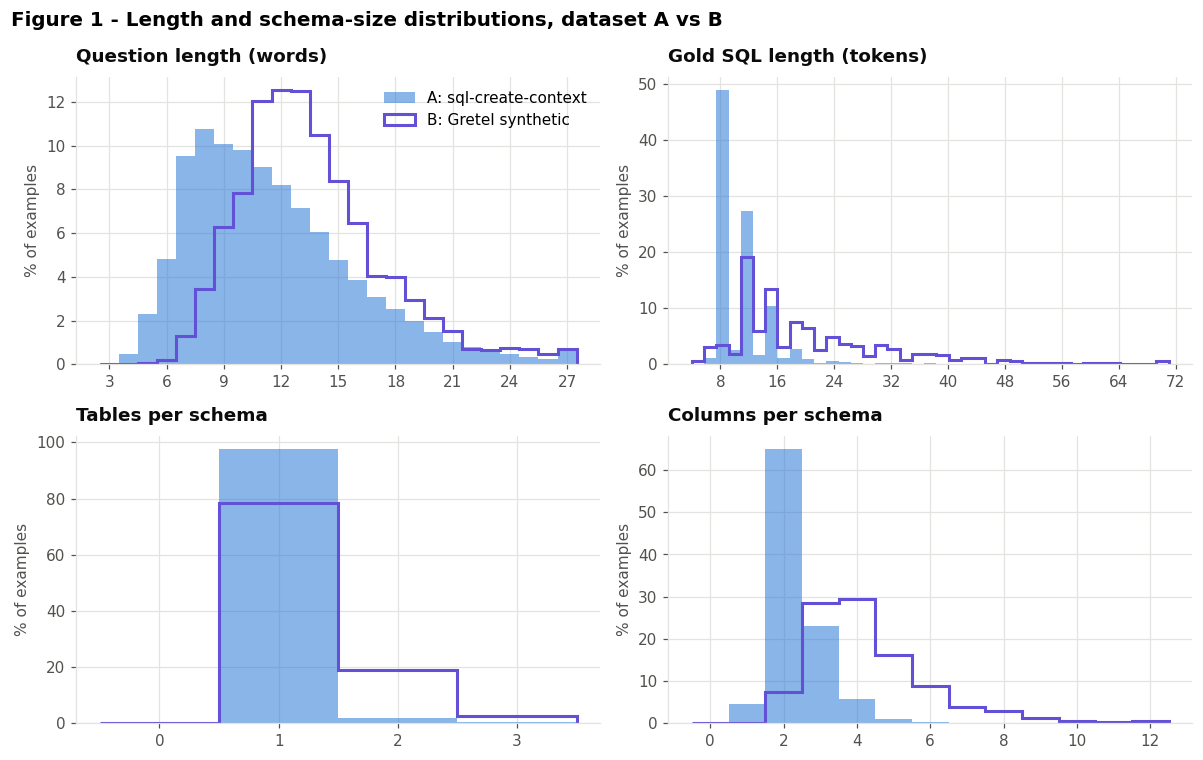

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
panels = [("question_words", "Question length (words)"), ("sql_tokens", "Gold SQL length (tokens)"),
          ("n_tables", "Tables per schema"), ("n_columns", "Columns per schema")]
for ax, (col, title) in zip(axes.ravel(), panels):
    hi = int(max(np.percentile(full_A[col], 99.5), np.percentile(eda_B[col], 99.5)))
    lo = int(min(full_A[col].min(), eda_B[col].min()))
    bins = np.arange(lo, hi + 2) - 0.5 if hi - lo < 40 else np.linspace(lo, hi, 40)
    for df, c, lab, kw in [(full_A, A_C, "A: sql-create-context", {"alpha": 0.55}),
                           (eda_B, B_C, "B: Gretel synthetic", {"histtype": "step", "linewidth": 2})]:
        w = np.full(len(df), 100 / len(df))
        ax.hist(df[col].clip(upper=hi), bins=bins, weights=w, color=c, label=lab, **kw)
    ax.set_title(title); ax.set_ylabel("% of examples")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[0, 0].legend(loc="upper right")
fig.suptitle("Figure 1 - Length and schema-size distributions, dataset A vs B", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
savefig(fig, "fig01_distributions", "Length and schema-size distributions, A vs B")

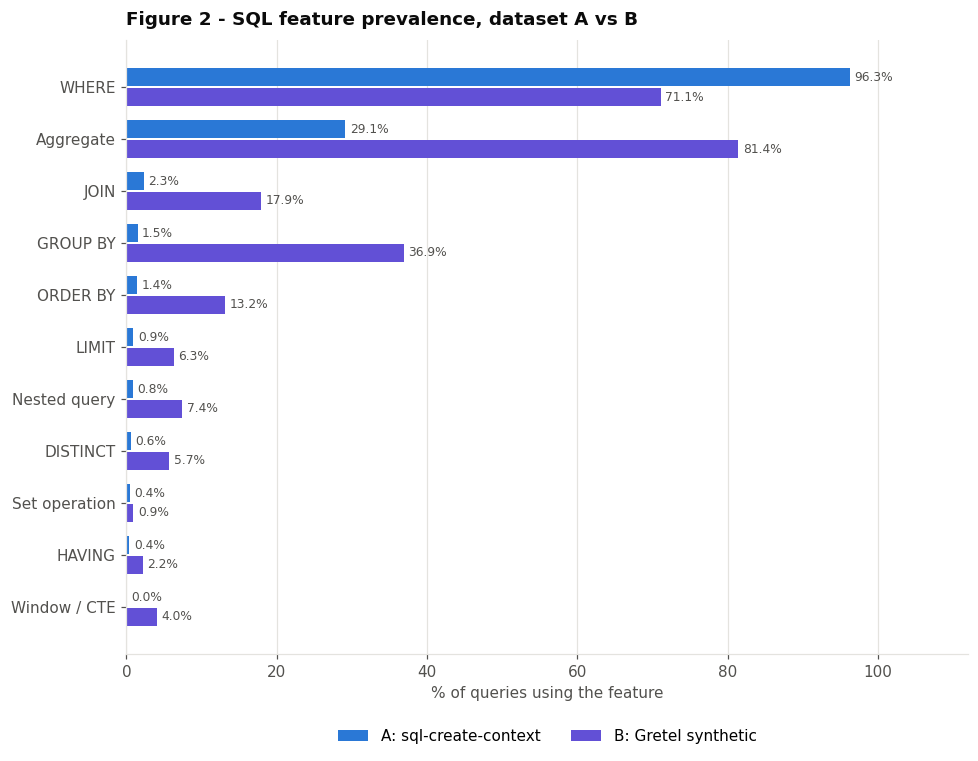

In [ ]:
feat_cols = [f"has_{k}" for k in FEATURES]
prev = pd.DataFrame({"A": full_A[feat_cols].mean() * 100, "B": eda_B[feat_cols].mean() * 100})
prev.index = [c[4:] for c in prev.index]
prev = prev[(prev > 0).any(axis=1)].sort_values("A")
fig, ax = plt.subplots(figsize=(9, 0.5 * len(prev) + 1.5))
y = np.arange(len(prev)); h = 0.38
label_bars(ax, ax.barh(y + h / 2, prev["A"], h - 0.03, color=A_C, label="A: sql-create-context"), "{:.1f}%", True)
label_bars(ax, ax.barh(y - h / 2, prev["B"], h - 0.03, color=B_C, label="B: Gretel synthetic"), "{:.1f}%", True)
ax.set_yticks(y); ax.set_yticklabels(prev.index); ax.set_xlim(0, 112); ax.grid(axis="y", visible=False)
ax.set_xlabel("% of queries using the feature")
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.1))
ax.set_title("Figure 2 - SQL feature prevalence, dataset A vs B")
savefig(fig, "fig02_sql_features", "SQL feature prevalence, A vs B")

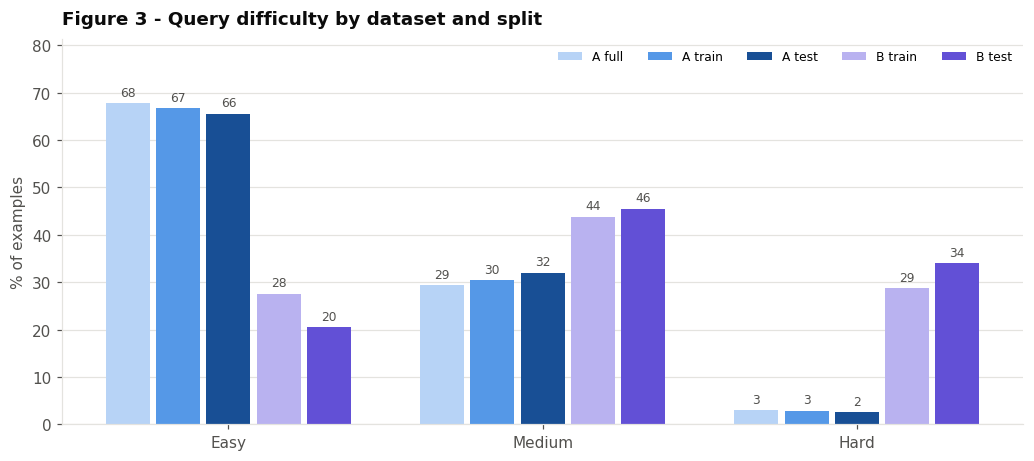

Chi-square, A train vs A test difficulty: chi2=0.29, p=0.864 -> no significant difference (representative split)


In [ ]:
diff_rows = {
    "A full": full_A["difficulty"], "A train": full_A.loc[full_A.split == "train", "difficulty"],
    "A test": full_A.loc[full_A.split == "test", "difficulty"],
    "B train": eda_B.loc[eda_B.split == "train", "difficulty"], "B test": eda_Bt["difficulty"]}
diff_tab = pd.DataFrame({k: v.value_counts(normalize=True).reindex(DIFF_ORDER).fillna(0) * 100
                         for k, v in diff_rows.items()}).T
fig, ax = plt.subplots(figsize=(9.5, 4.3))
w = 0.16
colors = ["#b7d3f6", "#5598e7", "#184f95", "#b9b2f0", B_C]
for i, (g, c) in enumerate(zip(diff_tab.index, colors)):
    label_bars(ax, ax.bar(np.arange(3) + (i - 2) * w, diff_tab.loc[g], w - 0.02, color=c, label=g), "{:.0f}")
ax.set_xticks(range(3)); ax.set_xticklabels(DIFF_ORDER); ax.set_ylabel("% of examples")
ax.set_ylim(0, diff_tab.values.max() * 1.2); ax.legend(ncol=5, loc="upper right", fontsize=8); ax.grid(axis="x", visible=False)
ax.set_title("Figure 3 - Query difficulty by dataset and split")
savefig(fig, "fig03_difficulty_splits", "Difficulty distribution across datasets and splits")

counts = pd.crosstab(full_A["split"], full_A["difficulty"]).reindex(index=["train", "test"], columns=DIFF_ORDER).fillna(0)
counts = counts.loc[:, counts.sum() > 0]
chi2, p_split, *_ = chi2_contingency(counts.values)
print(f"Chi-square, A train vs A test difficulty: chi2={chi2:.2f}, p={p_split:.3f} -> "
      f"{'no significant difference (representative split)' if p_split > 0.05 else 'distributions differ'}")

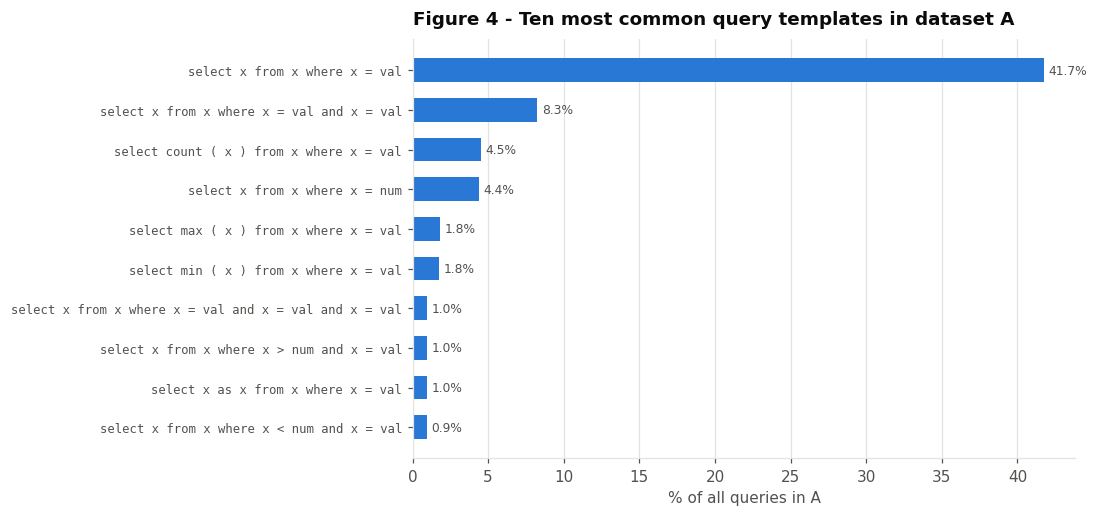

Distinct templates - A: 4,040 (top 10 cover 66.3%) | B pool: 1,438 of 2,500 queries


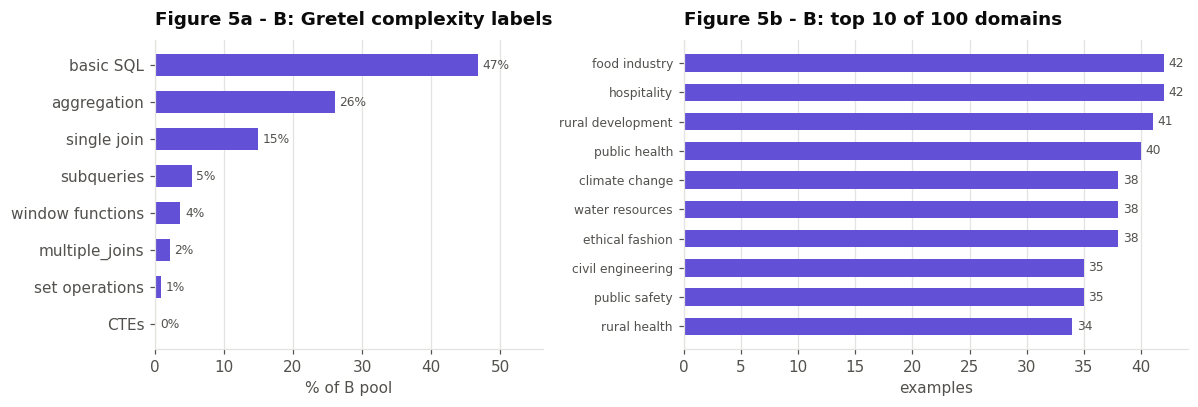

In [ ]:
top = full_A["skeleton"].value_counts().head(10)
fig, ax = plt.subplots(figsize=(10, 4.8))
labels = [s if len(s) < 70 else s[:67] + "..." for s in top.index][::-1]
label_bars(ax, ax.barh(labels, (100 * top.values / len(full_A))[::-1], color=A_C, height=0.6), "{:.1f}%", True)
ax.set_xlabel("% of all queries in A"); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8)
for t in ax.get_yticklabels(): t.set_fontfamily("monospace")
ax.set_title("Figure 4 - Ten most common query templates in dataset A")
savefig(fig, "fig04_templates", "Most common query templates in A")
print(f"Distinct templates - A: {full_A['skeleton'].nunique():,} (top 10 cover {100 * top.sum() / len(full_A):.1f}%) | "
      f"B pool: {eda_B['skeleton'].nunique():,} of {len(eda_B):,} queries")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.3]})
cx = eda_B["complexity"].value_counts(normalize=True).sort_values() * 100
label_bars(ax1, ax1.barh(cx.index, cx.values, color=B_C, height=0.6), "{:.0f}%", True)
ax1.set_xlabel("% of B pool"); ax1.grid(axis="y", visible=False); ax1.set_xlim(0, cx.max() * 1.2)
ax1.set_title("Figure 5a - B: Gretel complexity labels")
dm = eda_B["domain"].value_counts().head(10).sort_values()
label_bars(ax2, ax2.barh(dm.index, dm.values, color=B_C, height=0.6), "{:.0f}", True)
ax2.set_xlabel("examples"); ax2.grid(axis="y", visible=False); ax2.tick_params(axis="y", labelsize=8)
ax2.set_title(f"Figure 5b - B: top {len(dm)} of {eda_B['domain'].nunique()} domains")
savefig(fig, "fig05_gretel_profile", "Dataset B complexity labels and domains")

In [ ]:
norm_q = lambda s: re.sub(r"\s+", " ", s.lower().strip())
def leakage(train, test, name):
    tq = set(norm_q(r["question"]) for r in train)
    tp = set((norm_q(r["question"]), r["context"]) for r in train)
    lq = sum(norm_q(r["question"]) in tq for r in test)
    lp = sum((norm_q(r["question"]), r["context"]) in tp for r in test)
    return {"dataset": name, "test questions also in train": lq, "identical (question, schema) pairs": lp,
            "test size": len(test)}
display(pd.DataFrame([leakage(train_A + val_A + tune_A, test_A, "A"), leakage(pool_B, test_B, "B"),
                      leakage(train_A, tune_A, "A (train vs tuning set)")]))

,dataset,test questions also in train,"identical (question, schema) pairs",test size
0,A,0,0,200
1,B,0,0,200
2,A (train vs tuning set),0,0,300


## 4. Evaluation metrics

All metrics are computed on the same held-out test examples for every model, with greedy decoding.

| Metric | Definition | Why it matters |
|---|---|---|
| **Execution Accuracy (EX)** — *primary* | Gold and predicted SQL return the same result on 3 databases per example. For B, database 1 is the **real sample data** from the context; the others add random rows seeded with the query's literals. Order-sensitive only if the gold query has ORDER BY | Rewards *semantically* correct SQL even if written differently |
| **Exact Match (EM)** | Normalised prediction == normalised gold | Strict; underestimates accuracy |
| **Valid SQL** | Prediction executes in SQLite against the schema | Syntax + correct table/column names |
| **Token F1** | F1 over SQL tokens of prediction vs gold | Partial credit |
| **Format compliance** | Output is *only* a SQL query (no prose, no code fences) | Usability as a component |

$$\text{EX}=\frac{1}{N}\sum_{i=1}^{N}\mathbb{1}\big[\forall d\in D_i:\ \text{exec}_d(\hat y_i)=\text{exec}_d(y_i)\big],\qquad \text{Token F1}=\frac{2PR}{P+R}$$

**Uncertainty:** 95% percentile-bootstrap CIs (2,000 resamples) and mean ± SD over 3 training seeds.
**Significance:** McNemar's exact test on paired per-example correctness.

In [ ]:
SYSTEM = ("You are a text-to-SQL assistant. Given a database schema and a question, "
          "reply with a single SQLite query and nothing else.")

def _user_msg(row):
    return {"role": "user", "content": f"Schema:\n{row['context']}\n\nQuestion: {row['question']}"}

def build_prompt(row, shots=None):
    msgs = [{"role": "system", "content": SYSTEM}]
    for s in shots or []:                                     # few-shot: worked examples as earlier turns
        msgs += [_user_msg(s), {"role": "assistant", "content": s["answer"]}]
    msgs.append(_user_msg(row))
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False)

def pick_shots(rows, k=N_SHOTS):
    """One example per difficulty level (Easy, Medium, Hard), shortest first, so the prompt stays small."""
    chosen = []
    for d in DIFF_ORDER:
        cands = sorted([r for r in rows if difficulty(r["answer"]) == d], key=lambda r: len(r["context"]))
        if cands:
            chosen.append(cands[0])
    for r in rows:
        if len(chosen) >= k: break
        if r not in chosen: chosen.append(r)
    return chosen[:k]

SHOTS_A = pick_shots(train_A[:500])
SHOTS_B = pick_shots(pool_B[N_TRAIN + N_VAL:])                # B shots come from outside its train/val split

def clean_output(text):
    return re.sub(r"<think>.*?</think>", "", text, flags=re.S).strip()

def extract_sql(text):
    text = clean_output(text)
    m = re.search(r"```(?:sql|sqlite)?\s*(.*?)```", text, flags=re.S | re.I)
    if m:
        text = m.group(1)
    else:
        m = re.search(r"\b(select|with)\b.*", text, flags=re.S | re.I)     # drop leading prose
        text = m.group(0) if m else text
    return text.strip().split(";")[0].strip()

def format_compliant(raw):
    t = clean_output(raw).strip().rstrip(";").strip()
    return bool(re.match(r"(?is)^(select|with)\b", t)) and "```" not in t and t == extract_sql(raw)

def normalize(sql):
    sql = sql.replace('"', "'").lower()
    sql = re.sub(r"\s+", " ", sql)
    sql = re.sub(r"\s*([(),=<>*])\s*", r"\1", sql)
    return sql.strip().rstrip(";").strip()

def token_f1(pred, gold):
    p, g = collections.Counter(sql_tokens(normalize(pred))), collections.Counter(sql_tokens(normalize(gold)))
    overlap = sum((p & g).values())
    if overlap == 0:
        return 0.0
    prec, rec = overlap / sum(p.values()), overlap / sum(g.values())
    return 2 * prec * rec / (prec + rec)

def is_valid_sql(sql, schema):
    return sqlite_ok(schema, sql)

# ---------- execution accuracy ----------
NUMERIC_TYPES = ("INT", "REAL", "NUM", "DEC", "FLOAT", "DOUB")
WORDS = ["alpha", "beta", "gamma", "delta", "north", "south", "red", "blue", "x1", "y2"]

def literals(sql):
    strs = [s[1:-1] for s in STR_RE.findall(sql)]
    nums = NUM_RE.findall(STR_RE.sub(" ", sql))
    return strs, nums

def _as_number(v):
    f = float(v)
    return int(f) if f.is_integer() else f

def _rand_value(rng, ctype, strs, nums):
    if rng.random() < 0.1:
        return None                                   # NULLs separate COUNT(col) from COUNT(other_col)
    if (strs or nums) and rng.random() < 0.5:         # reuse the gold query's literals so filters match rows
        v = rng.choice(strs + nums)
        return _as_number(v) if v in nums else v
    if any(t in ctype.upper() for t in NUMERIC_TYPES):
        return rng.randint(0, 100)
    return rng.choice(WORDS + [str(rng.randint(0, 100))])

def build_dbs(context, gold, n_dbs=N_EXEC_DBS, rows=ROWS_PER_TABLE):
    strs, nums = literals(gold)
    has_rows = bool(re.search(r"\binsert\b", context, re.I))
    dbs = []
    for k in range(n_dbs):
        rng = random.Random(zlib.crc32(f"{context}|{gold}|{k}|{SEED}".encode()))
        con = sqlite3.connect(":memory:")
        try:
            con.executescript(context)                # B: includes the real sample rows
            if not (has_rows and k == 0):             # B's first database = real data only
                tables = [r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type='table'")]
                for t in tables:
                    cols = con.execute(f'PRAGMA table_info("{t}")').fetchall()
                    q = f'INSERT INTO "{t}" VALUES ({",".join("?" * len(cols))})'
                    for _ in range(rows):
                        try:
                            con.execute(q, [_rand_value(rng, c[2] or "", strs, nums) for c in cols])
                        except Exception:
                            pass
        except Exception:
            pass
        dbs.append(con)
    return dbs

def _run(con, sql, timeout=2.0):
    start = time.time()
    con.set_progress_handler(lambda: 1 if time.time() - start > timeout else 0, 1000)
    try:
        rows = con.execute(sql).fetchmany(5000)
    finally:
        con.set_progress_handler(None, 1000)
    return [tuple(round(v, 6) if isinstance(v, float) else v for v in r) for r in rows]

def exec_match(pred, gold, dbs):
    """True/False, or None if the gold query cannot run on the first database (excluded from EX)."""
    ordered = bool(re.search(r"\border\s+by\b", gold, re.I))
    for k, con in enumerate(dbs):
        try:
            g = _run(con, gold)
        except Exception:
            if k == 0:
                return None
            continue
        try:
            p = _run(con, pred)
        except Exception:
            return False
        if (g != p) if ordered else (collections.Counter(g) != collections.Counter(p)):
            return False
    return True

def gold_nonempty(gold, dbs):
    try:
        return any(len(_run(con, gold)) > 0 for con in dbs)
    except Exception:
        return False

# ---------- error taxonomy ----------
def _idents(sql):
    s = STR_RE.sub(" ", sql.lower())
    return {t for t in re.findall(r"[a-z_][a-z0-9_]*", s) if t not in SQL_KEYWORDS}

def _tables(sql):
    return {t.lower().strip('`"') for t in re.findall(r"\b(?:from|join)\s+([`\"]?\w+)", STR_RE.sub(" ", sql), re.I)}

ERROR_ORDER = ["Invalid SQL", "Wrong table", "Wrong column", "Wrong literal value", "Wrong aggregation",
               "Wrong clause / structure"]

def error_type(pred, gold, valid):
    if not valid:
        return "Invalid SQL"
    if _tables(pred) != _tables(gold):
        return "Wrong table"
    if _idents(pred) - _tables(pred) != _idents(gold) - _tables(gold):
        return "Wrong column"
    lp, lg = literals(pred), literals(gold)
    if sorted(lp[0] + lp[1]) != sorted(lg[0] + lg[1]):          # case-sensitive: 'france' != 'France' in SQLite
        return "Wrong literal value"
    if sorted(m.lower() for m in AGG_RE.findall(pred)) != sorted(m.lower() for m in AGG_RE.findall(gold)):
        return "Wrong aggregation"
    return "Wrong clause / structure"

# ---------- per-example scoring + summaries ----------
def score(preds, raws, rows, dbs_list):
    recs = []
    for p, raw, r, dbs in zip(preds, raws, rows, dbs_list):
        valid = is_valid_sql(p, r["context"])
        ex = exec_match(p, r["answer"], dbs)
        em = normalize(p) == normalize(r["answer"])
        correct = ex if ex is not None else em
        recs.append({
            "question": r["question"], "gold": r["answer"], "pred": p, "raw_output": raw,
            "em": em, "ex": ex, "valid": valid, "token_f1": token_f1(p, r["answer"]),
            "format_ok": format_compliant(raw), "correct": bool(correct),
            "pred_tokens": len(sql_tokens(p)), "difficulty": difficulty(r["answer"]),
            "error_type": "Correct" if correct else error_type(p, r["answer"], valid),
            **{f"has_{k}": fn(r["answer"]) for k, fn in FEATURES.items()},
        })
    return pd.DataFrame(recs)

def bootstrap_ci(x, n=N_BOOT, seed=SEED):
    x = np.asarray([v for v in x if v is not None and not (isinstance(v, float) and np.isnan(v))], float)
    if len(x) == 0:
        return (np.nan, np.nan, np.nan)
    means = np.random.default_rng(seed).choice(x, (n, len(x))).mean(1)
    return 100 * x.mean(), 100 * np.percentile(means, 2.5), 100 * np.percentile(means, 97.5)

METRICS = [("ex", "Execution Accuracy"), ("em", "Exact Match"), ("valid", "Valid SQL"),
           ("token_f1", "Token F1"), ("format_ok", "Format compliance")]

def summarize(df):
    return {m: bootstrap_ci(df[m].tolist()) for m, _ in METRICS}

def mcnemar(a, b):
    """a, b: boolean arrays (model 1 correct, model 2 correct). Exact binomial McNemar test."""
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    n01, n10 = int((~a & b).sum()), int((a & ~b).sum())
    p = binomtest(n01, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
    return n01, n10, p

In [ ]:
t0 = time.time()
EVAL_SETS = {}
for name, rows, shots in [("A_test", test_A, SHOTS_A), ("B_test", test_B, SHOTS_B), ("A_tune", tune_A, SHOTS_A)]:
    EVAL_SETS[name] = (rows, [build_dbs(r["context"], r["answer"]) for r in rows], shots)

sanity = []
for name, (rows, dbs, _) in EVAL_SETS.items():
    golds = [r["answer"] for r in rows]
    gold_ex = [exec_match(g, g, d) for g, d in zip(golds, dbs)]
    const_ex = [exec_match("SELECT 1", g, d) for g, d in zip(golds, dbs)]
    sanity.append({
        "eval set": name,
        "gold executable (%)": 100 * np.mean([x is not None for x in gold_ex]),
        "gold vs itself EX (must be 100)": 100 * np.mean([x for x in gold_ex if x is not None]),
        "'SELECT 1' EX (should be ~0)": 100 * np.mean([x for x in const_ex if x is not None]),
        "gold non-empty on >= 1 DB (%)": 100 * np.mean([gold_nonempty(g, d) for g, d in zip(golds, dbs)]),
    })
sanity = pd.DataFrame(sanity).set_index("eval set").round(1)
display(sanity)
print(f"Built {sum(len(v[1]) for v in EVAL_SETS.values()) * N_EXEC_DBS} databases in {time.time() - t0:.1f}s")
assert (sanity["gold vs itself EX (must be 100)"] == 100).all(), "EX of gold vs gold must be 100%"
print("\nFew-shot examples for A:", [s["answer"] for s in SHOTS_A])

,gold executable (%),gold vs itself EX (must be 100),'SELECT 1' EX (should be ~0),gold non-empty on >= 1 DB (%)
eval set,,,,
A_test,97.0,100.0,0.0,92.5
B_test,100.0,100.0,1.5,96.5
A_tune,98.3,100.0,0.0,90.3


Built 2100 databases in 0.8s

Few-shot examples for A: ['SELECT * FROM hiring', 'SELECT 2004 FROM table_name_74 WHERE 2005 = "2r" AND 2006 = "1r"', 'SELECT Status FROM roller_coaster GROUP BY Status HAVING COUNT(*) > 2']


## 5. Model, generation and training functions

One function, experiment(...), does everything for a single configuration: load a fresh base model → (optionally) LoRA fine-tune → generate on the requested evaluation sets → score → save to the run cache. Every result below comes from this function, so all models are treated identically.

**Fine-tuning ** :

| Setting | Value |
|---|---|
| Method | Supervised fine-tuning with LoRA on 16-bit weights (QLoRA not recommended for Qwen3.5) |
| LoRA | *rank r*, *alpha = r × alpha_mult*, dropout 0, *target modules* (attention only, or attention + MLP) |
| Loss | Cross-entropy on the **answer tokens only** (prompt masked to −100) |
| Optimiser | AdamW 8-bit, *learning rate*, linear decay, warm-up, weight decay 0.01, *epochs* |
| Batch | effective 16 (4 × 4; 2 × 8 for the 4B model) |

In [ ]:
TARGETS = {"attn": ["q_proj", "k_proj", "v_proj", "o_proj"],
           "all":  ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]}

def load_model(model_name, four_bit=False):
    global tok, IM_END_ID
    model, tokenizer = FastLanguageModel.from_pretrained(
        model_name=model_name, max_seq_length=MAX_SEQ_LEN,
        load_in_4bit=four_bit, load_in_16bit=not four_bit, full_finetuning=False)
    tok = tokenizer.tokenizer if hasattr(tokenizer, "tokenizer") else tokenizer   # Qwen3.5 is a unified VLM
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    IM_END_ID = tok.convert_tokens_to_ids("<|im_end|>")
    return model, tokenizer

def to_text(row):
    return {"text": build_prompt(row) + row["answer"] + "<|im_end|>"}

@torch.no_grad()
def generate(model, rows, shots=None, batch_size=GEN_BATCH_SIZE, max_new_tokens=MAX_NEW_TOKENS):
    FastLanguageModel.for_inference(model)
    tok.padding_side = "left"                      # left-pad for batched generation
    raws, t0 = [], time.time()
    bs = max(1, batch_size // 2) if shots else batch_size
    for i in tqdm(range(0, len(rows), bs), desc="generating", leave=False):
        batch = rows[i:i + bs]
        enc = tok([build_prompt(r, shots) for r in batch], return_tensors="pt", padding=True,
                  add_special_tokens=False).to("cuda")
        out = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                             pad_token_id=tok.pad_token_id, eos_token_id=IM_END_ID)
        raws += tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    secs = (time.time() - t0) / len(rows)
    tok.padding_side = "right"
    return [extract_sql(r) for r in raws], raws, secs

def finetune(model, tokenizer, train_rows, val_rows, hp, seed, size_tag="0.8B", tag="run", verbose=True):
    FastLanguageModel.for_training(model)
    model = FastLanguageModel.get_peft_model(
        model, r=hp["lora_r"], lora_alpha=hp["lora_r"] * hp["alpha_mult"], lora_dropout=0, bias="none",
        target_modules=TARGETS[hp["targets"]], use_gradient_checkpointing="unsloth",
        random_state=seed, max_seq_length=MAX_SEQ_LEN)
    tr = Dataset.from_list([to_text(r) for r in train_rows])
    va = Dataset.from_list([to_text(r) for r in val_rows]) if val_rows else None
    bsz, acc = BATCH_BY_SIZE.get(size_tag, (4, 4))
    steps = math.ceil(len(tr) / (bsz * acc)) * hp["epochs"]
    args = SFTConfig(
        dataset_text_field="text", max_length=MAX_SEQ_LEN,
        per_device_train_batch_size=bsz, gradient_accumulation_steps=acc,
        num_train_epochs=hp["epochs"], learning_rate=hp["lr"], lr_scheduler_type="linear",
        warmup_steps=max(1, min(10, steps // 10)), weight_decay=0.01, optim="adamw_8bit",
        fp16=not is_bfloat16_supported(), bf16=is_bfloat16_supported(),
        logging_steps=max(1, steps // 40),
        eval_strategy="steps" if va is not None else "no", eval_steps=max(1, steps // 8),
        per_device_eval_batch_size=8, output_dir=f"{OUT_DIR}/outputs_tmp",
        save_strategy="no", report_to="none", seed=seed, dataset_num_proc=1)
    trainer = SFTTrainer(model=model, processing_class=tokenizer, train_dataset=tr, eval_dataset=va, args=args)
    trainer = train_on_responses_only(trainer, instruction_part="<|im_start|>user\n",
                                      response_part="<|im_start|>assistant\n<think>\n\n</think>\n\n", tokenizer=tok)
    kept = tok.decode([t for t in trainer.train_dataset[0]["labels"] if t != -100])
    assert "<|im_start|>" not in kept and "Schema:" not in kept and kept, f"Masking failed: {kept!r}"
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    if verbose:
        print(f"[{tag}] {len(tr)} ex, {steps} steps, hp={hp}, seed={seed} | trainable {trainable / 1e6:.2f}M "
              f"({100 * trainable / total:.2f}%)")
    torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    stats = trainer.train()
    assert not math.isnan(stats.training_loss), "Loss is NaN (fp16 overflow) - lower the learning rate"
    ev = [x["eval_loss"] for x in trainer.state.log_history if "eval_loss" in x]
    info = {"train_examples": len(tr), "steps": trainer.state.global_step,
            "train_time_min": (time.time() - t0) / 60, "peak_vram_gb": torch.cuda.max_memory_allocated() / 1e9,
            "final_train_loss": stats.training_loss, "final_val_loss": ev[-1] if ev else None,
            "trainable_params_M": trainable / 1e6, "total_params_M": total / 1e6}
    return model, trainer, info

def experiment(key, model_name=MODEL_NAME, size_tag="0.8B", train_rows=None, hp=None, seed=SEED,
               evals=("A_test",), shots=False, val_rows=None, four_bit=False, save_adapter=False):
    """Train (optional) + evaluate one configuration. Cached: re-running returns the saved result."""
    key = safe_key(PFX + key)
    rec = load_run(key)
    save_adapter = bool(train_rows) and (save_adapter or SAVE_ALL_ADAPTERS)
    adapter_path = f"{ADAPTER_DIR}/{key}"
    adapter_ok = (not save_adapter) or os.path.exists(f"{adapter_path}/adapter_config.json")
    if rec is not None and all(e in rec["eval"] for e in evals) and adapter_ok:
        print(f"[cached] {key}")
        return rec
    if rec is not None and not adapter_ok:
        print(f"[retrain] {key}: results are cached but the adapter was not saved yet - retraining to save it")
    t0 = time.time()
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    model = tokenizer = trainer = None
    try:
        model, tokenizer = load_model(model_name, four_bit=four_bit)
        rec = {"key": key, "model": model_name, "size": size_tag, "hp": hp, "seed": seed, "shots": shots,
               "four_bit": four_bit, "n_train": len(train_rows) if train_rows else 0, "eval": {}, "train": None,
               "log": [], "total_params_M": sum(p.numel() for p in model.parameters()) / 1e6}
        if train_rows:
            model, trainer, info = finetune(model, tokenizer, train_rows, val_rows, hp, seed, size_tag, tag=key)
            rec["train"] = info
            rec["log"] = [{k: float(v) for k, v in x.items() if isinstance(v, (int, float))}
                          for x in trainer.state.log_history]
            if save_adapter:
                model.save_pretrained(adapter_path); tokenizer.save_pretrained(adapter_path)
                json.dump({"base_model": model_name, "hp": hp, "seed": seed, "four_bit": four_bit,
                           "n_train": len(train_rows), "key": key}, open(f"{adapter_path}/run_info.json", "w"), indent=2)
                rec["adapter_path"] = adapter_path
                print(f"[saved adapter] {adapter_path}")
        for name in evals:
            rows, dbs, shot_rows = EVAL_SETS[name]
            preds, raws, secs = generate(model, rows, shots=shot_rows if shots else None)
            df = score(preds, raws, rows, dbs)
            rec["eval"][name] = {"summary": summarize(df), "secs_per_example": secs, "df": df}
        rec["wall_min"] = (time.time() - t0) / 60
        save_run(rec)
        print(f"[done] {key}: " + " | ".join(f"{n} EX={rec['eval'][n]['summary']['ex'][0]:.1f}" for n in evals)
              + f" ({rec['wall_min']:.1f} min)")
        return rec
    finally:
        del model, tokenizer, trainer       # always release GPU memory, even if the run crashed
        free_gpu()

def is_oom(e):
    return "out of memory" in str(e).lower()

def ex_of(rec, name="A_test", metric="ex"):
    return rec["eval"][name]["summary"][metric][0]

==((====))==  Unsloth 2026.10.8: Fast Qwen3_5 patching. Transformers: 5.16.1.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for qwen3_5 won't work! Using float32.


/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:299: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

Example prompt fed to the model:
------------------------------------------------------------
<|im_start|>system
You are a text-to-SQL assistant. Given a database schema and a question, reply with a single SQLite query and nothing else.<|im_end|>
<|im_start|>user
Schema:
CREATE TABLE table_name_93 (game INTEGER, record VARCHAR)

Question: Name the least game for record of 5-1-3<|im_end|>
<|im_start|>assistant
<think>

</think>




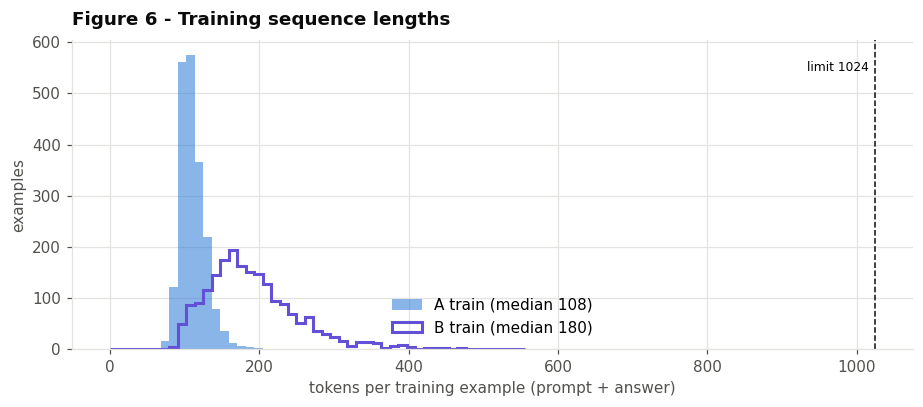

A train: mean 110, max 223, truncated: 0.00%
B train: mean 191, max 556, truncated: 0.00%


In [ ]:
# ---------- token lengths with the real tokenizer (checks that MAX_SEQ_LEN does not truncate) ----------
model, tokenizer = load_model(MODEL_NAME)
lens = {name: np.array([len(tok(to_text(r)["text"], add_special_tokens=False)["input_ids"]) for r in rows])
        for name, rows in [("A train", train_A), ("B train", train_B)]}
print("Example prompt fed to the model:\n" + "-" * 60 + "\n" + build_prompt(test_A[0]))
del model, tokenizer; free_gpu()

fig, ax = plt.subplots(figsize=(8.5, 3.8))
hi = max(v.max() for v in lens.values())
bins = np.linspace(0, hi, 50)
for (name, v), c, kw in zip(lens.items(), [A_C, B_C], [{"alpha": 0.55}, {"histtype": "step", "linewidth": 2}]):
    ax.hist(v, bins=bins, color=c, label=f"{name} (median {np.median(v):.0f})", **kw)
ax.axvline(MAX_SEQ_LEN, color=INK, linestyle="--", linewidth=1)
ax.annotate(f"limit {MAX_SEQ_LEN}", (MAX_SEQ_LEN, ax.get_ylim()[1] * 0.9), xytext=(-4, 0),
            textcoords="offset points", ha="right", fontsize=8)
ax.set_xlabel("tokens per training example (prompt + answer)"); ax.set_ylabel("examples"); ax.legend()
ax.set_title("Figure 6 - Training sequence lengths")
savefig(fig, "fig06_token_lengths", "Training sequence lengths in tokens")
for name, v in lens.items():
    print(f"{name}: mean {v.mean():.0f}, max {v.max()}, truncated: {(v > MAX_SEQ_LEN).mean() * 100:.2f}%")


## 6. Stage 1 — Hyperparameter Study

In our initial experiment, we used a LoRA rank of 16, a learning rate of 2e-4, and trained the model for one epoch. These values are commonly used when fine-tuning models with LoRA, but that does not necessarily mean they are the best choices for our dataset. So, in this stage, we experiment with different hyperparameter values to see which ones work better.

### How we conduct the experiments

1. We start with the default configuration and train the model on 2,000 examples from Dataset A. We then change one hyperparameter at a time while keeping the others fixed. This helps us understand the effect of each parameter individually.

2. After each training run, we evaluate the model using Execution Accuracy on a separate tuning set containing 300 examples. We do not use the test sets during this process.

3. For each hyperparameter, we select the value that gives the highest Execution Accuracy. However, if the difference is less than 1 percentage point (`TUNE_TOL`), which is roughly 3 examples out of 300, we consider the results close enough to be a tie. In such cases, we prefer the simpler or less computationally expensive option, such as a smaller LoRA rank or fewer training epochs.

4. Once we have selected the hyperparameters individually, we combine them into a single configuration and train the model again. If this combined configuration performs at least as well as the best individual run, within our tolerance, we keep it. Otherwise, we use the configuration from the best individual run.

### Choosing the LoRA Rank

One of the main hyperparameters we want to investigate is the LoRA rank. It determines the size of the low-rank matrices used during fine-tuning and affects the number of trainable parameters.

There is no single rank that works best for every model or dataset. Mathematically, the rank cannot exceed the smaller dimension of the weight matrix, but this limit is much larger than the values we typically use in practice.

Rather than assuming that a higher rank will give better results, we test five different values:

`r = {4, 8, 16, 32, 64}`

We then compare their Execution Accuracy to see whether increasing the rank actually helps our text-to-SQL task or simply adds more trainable parameters without much improvement.


In [ ]:
best_cfg_path = f"{RUN_DIR}/{PFX}best_config.json"
tune_rows = []
if RUN_TUNING:
    variants = [("baseline", "-", dict(BASE_HP))]
    for factor, vals in TUNE_GRID.items():
        for v in vals:
            if v != BASE_HP[factor]:
                variants.append((factor, v, {**BASE_HP, factor: v}))
    print(f"Stage 1: {len(variants)} configurations (+1 combined)")
    for factor, val, hp in variants:
        rec = experiment(f"tune_{hp_key(hp)}", train_rows=train_A, hp=hp, seed=SEED, evals=("A_tune",),
                         val_rows=val_A)
        s = rec["eval"]["A_tune"]["summary"]
        tune_rows.append({"factor": factor, "value": val, **hp, "tune_EX": s["ex"][0], "EX_lo": s["ex"][1],
                          "EX_hi": s["ex"][2], "tune_EM": s["em"][0], "tune_valid": s["valid"][0],
                          "val_loss": rec["train"]["final_val_loss"], "train_min": rec["train"]["train_time_min"],
                          "trainable_M": rec["train"]["trainable_params_M"], "peak_vram_gb": rec["train"]["peak_vram_gb"]})
    tune_df = pd.DataFrame(tune_rows)

    def choose(factor):
        sub = tune_df[(tune_df.factor == factor) | (tune_df.factor == "baseline")].copy()
        sub["v"] = [BASE_HP[factor] if f == "baseline" else v for f, v in zip(sub.factor, sub.value)]
        best = sub.tune_EX.max()
        ties = sub[sub.tune_EX >= best - TUNE_TOL]
        if PREFER[factor] == "low":
            return min(ties.v)
        if BASE_HP[factor] in list(ties.v):
            return BASE_HP[factor]
        return ties.sort_values("tune_EX", ascending=False).v.iloc[0]

    chosen = {f: choose(f) for f in TUNE_GRID}
    combined = {**BASE_HP, **chosen}
    rec_c = experiment(f"tune_{hp_key(combined)}", train_rows=train_A, hp=combined, seed=SEED,
                       evals=("A_tune",), val_rows=val_A)
    comb_ex = ex_of(rec_c, "A_tune")
    best_single = tune_df.sort_values("tune_EX", ascending=False).iloc[0]
    best_single_hp = {k: best_single[k] for k in BASE_HP}
    if comb_ex >= best_single.tune_EX - TUNE_TOL:
        BEST_HP, how = combined, "combined per-factor choices"
    else:
        BEST_HP, how = best_single_hp, "best single configuration (combination did not help)"
    BEST_HP = {k: (int(v) if isinstance(v, (np.integer,)) else float(v) if isinstance(v, np.floating) else v)
               for k, v in BEST_HP.items()}
    json.dump({"best_hp": BEST_HP, "how": how, "combined_tune_EX": comb_ex,
               "baseline_tune_EX": float(tune_df.loc[tune_df.factor == "baseline", "tune_EX"].iloc[0])},
              open(best_cfg_path, "w"), indent=2)
elif os.path.exists(best_cfg_path):
    BEST_HP, how = json.load(open(best_cfg_path))["best_hp"], "loaded from an earlier tuning run"
else:
    BEST_HP, how = dict(BASE_HP), "default (tuning disabled)"
print(f"\nSELECTED CONFIGURATION ({how}): {BEST_HP}")

Stage 1: 12 configurations (+1 combined)
[cached] tune_r16_a1_lr0.0002_e1_all
[cached] tune_r4_a1_lr0.0002_e1_all
[cached] tune_r8_a1_lr0.0002_e1_all
[cached] tune_r32_a1_lr0.0002_e1_all
[cached] tune_r64_a1_lr0.0002_e1_all
[cached] tune_r16_a1_lr5e-05_e1_all
[cached] tune_r16_a1_lr0.0001_e1_all
[cached] tune_r16_a1_lr0.0005_e1_all
[cached] tune_r16_a1_lr0.0002_e2_all
[cached] tune_r16_a1_lr0.0002_e3_all
[cached] tune_r16_a1_lr0.0002_e1_attn
[cached] tune_r16_a2_lr0.0002_e1_all
[cached] tune_r16_a1_lr0.0002_e3_all

SELECTED CONFIGURATION (combined per-factor choices): {'lora_r': 16, 'alpha_mult': 1, 'lr': 0.0002, 'epochs': 3, 'targets': 'all'}


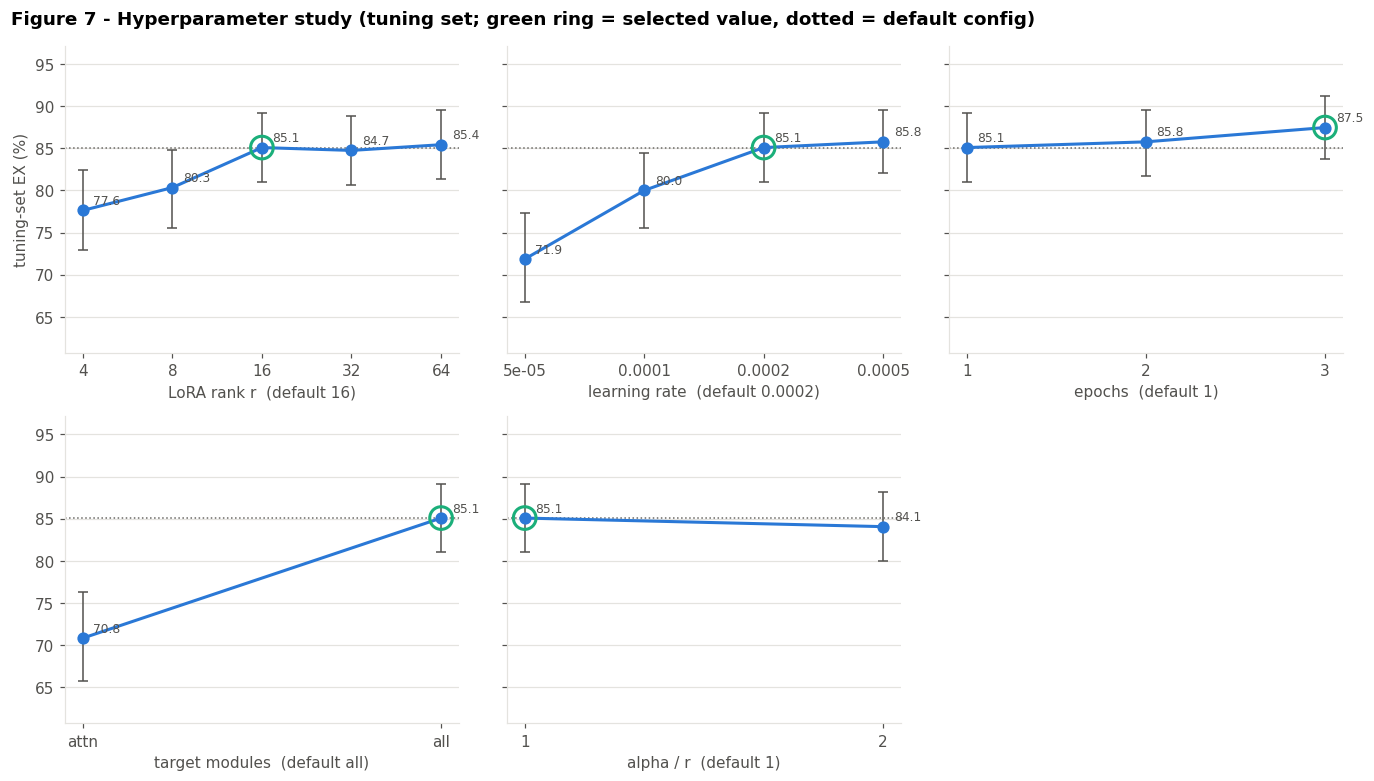

Table 2 - All Stage 1 runs (tuning set)


,factor,value,tune_EX,EX_lo,EX_hi,tune_EM,tune_valid,val_loss,trainable_M,train_min,peak_vram_gb
0,baseline,-,85.085,81.017,89.153,75.667,97.667,0.060,6.390,8.358,2.432
1,lora_r,4,77.627,72.881,82.373,65.667,98.000,0.086,1.597,4.781,2.914
2,lora_r,8,80.339,75.593,84.746,70.000,98.000,0.071,3.195,4.744,3.441
3,lora_r,32,84.746,80.678,88.814,76.333,98.000,0.050,12.780,4.768,4.010
4,lora_r,64,85.424,81.356,89.492,76.333,98.000,0.049,25.559,4.812,4.646
5,lr,0.00005,71.864,66.780,77.288,63.333,97.333,0.099,6.390,4.699,4.999
6,lr,0.0001,80.000,75.593,84.407,69.000,98.000,0.074,6.390,4.697,5.515
7,lr,0.0005,85.763,82.034,89.492,76.333,97.333,0.049,6.390,4.690,6.029
8,epochs,2,85.763,81.695,89.492,75.667,98.333,0.046,6.390,8.763,6.541
9,epochs,3,87.458,83.729,91.186,79.333,97.333,0.049,6.390,12.835,7.091


Table 3 - Sensitivity: how much tuning-set EX changes across each hyperparameter's values


,EX range across values (pp)
targets,14.2
lr,13.9
lora_r,7.8
epochs,2.4
alpha_mult,1.0


Table 4 - Default vs selected configuration


,default,selected
lora_r,16,16
alpha_mult,1,1
lr,0.0002,0.0002
epochs,1,3
targets,all,all


In [ ]:
if tune_rows:
    factors = list(TUNE_GRID)
    ncol = min(3, len(factors)); nrow = math.ceil(len(factors) / ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.6 * nrow), sharey=True, squeeze=False)
    ylo = max(0, tune_df.EX_lo.min() - 5); yhi = min(100, tune_df.EX_hi.max() + 6)
    base_ex = tune_df.loc[tune_df.factor == "baseline", "tune_EX"].iloc[0]
    for ax, f in zip(axes.ravel(), factors):
        sub = tune_df[(tune_df.factor == f) | (tune_df.factor == "baseline")].copy()
        sub["v"] = [BASE_HP[f] if x == "baseline" else v for x, v in zip(sub.factor, sub.value)]
        order = TUNE_GRID[f] if all(v in TUNE_GRID[f] for v in sub.v) else sorted(sub.v, key=str)
        sub = sub.set_index("v").loc[[v for v in order if v in set(sub.v)]]
        xs = np.arange(len(sub))
        ax.errorbar(xs, sub.tune_EX, yerr=[sub.tune_EX - sub.EX_lo, sub.EX_hi - sub.tune_EX], color=FT_C,
                    marker="o", markersize=7, capsize=3, elinewidth=1, ecolor=INK2)
        for x, (v, r) in zip(xs, sub.iterrows()):
            ax.annotate(f"{r.tune_EX:.1f}", (x, r.tune_EX), xytext=(7, 4), textcoords="offset points", fontsize=8, color=INK2)
            if v == BEST_HP[f]:
                ax.scatter([x], [r.tune_EX], s=220, facecolors="none", edgecolors=ACCENT, linewidths=2, zorder=5)
        ax.axhline(base_ex, color=GOLD_C, linestyle=":", linewidth=1)
        ax.set_xticks(xs); ax.set_xticklabels([f"{v:g}" if isinstance(v, float) else str(v) for v in sub.index])
        ax.set_xlabel(HP_LABELS[f] + ("  (default " + str(BASE_HP[f]) + ")")); ax.set_ylim(ylo, yhi)
        ax.grid(axis="x", visible=False)
    for ax in axes.ravel()[len(factors):]:
        ax.axis("off")
    axes[0, 0].set_ylabel("tuning-set EX (%)")
    fig.suptitle("Figure 7 - Hyperparameter study (tuning set; green ring = selected value, dotted = default config)",
                 x=0.01, ha="left", fontweight="bold", fontsize=12)
    savefig(fig, "fig07_hparam_study", "Hyperparameter study on the tuning set")

    show = tune_df[["factor", "value", "tune_EX", "EX_lo", "EX_hi", "tune_EM", "tune_valid", "val_loss",
                    "trainable_M", "train_min", "peak_vram_gb"]].round(3)
    print("Table 2 - All Stage 1 runs (tuning set)"); display(show)
    sens = {f: (pd.concat([tune_df[tune_df.factor == f].tune_EX, pd.Series([base_ex])]).max()
                - pd.concat([tune_df[tune_df.factor == f].tune_EX, pd.Series([base_ex])]).min()) for f in factors}
    sens_df = pd.Series(sens, name="EX range across values (pp)").sort_values(ascending=False).round(1)
    print("Table 3 - Sensitivity: how much tuning-set EX changes across each hyperparameter's values")
    display(sens_df.to_frame())
    chosen_tbl = pd.DataFrame({"default": BASE_HP, "selected": BEST_HP})
    print("Table 4 - Default vs selected configuration"); display(chosen_tbl)
    tune_df.to_csv(f"{OUT_DIR}/hparam_study.csv", index=False)

## 7. Stage 2 — Main comparison on the test sets

| Model | Training | Prompt |
|---|---|---|
| Zero-shot | none | instruction only |
| 3-shot | none | instruction + 3 worked examples (Easy / Medium / Hard) |
| Default LoRA | A-train, default config | instruction only |
| **Tuned LoRA** | A-train, **selected config**, **3 seeds** | instruction only |

Every model is evaluated on **A-test** (in-distribution) and **B-test** (different dataset, real sample data).

In [ ]:
EVALS = ("A_test", "B_test")
R = {}
R["zero"] = experiment("zero_0.8B", evals=EVALS)
if RUN_FEWSHOT:
    R["few"] = experiment("fewshot_0.8B", evals=EVALS, shots=True)
if RUN_DEFAULT_TEST and BEST_HP != BASE_HP:
    R["default"] = experiment(f"ftA_{hp_key(BASE_HP)}_s{SEEDS[0]}", train_rows=train_A, hp=BASE_HP,
                              seed=SEEDS[0], evals=EVALS, val_rows=val_A)
R["seeds"] = [experiment(f"ftA_{hp_key(BEST_HP)}_s{s}", train_rows=train_A, hp=BEST_HP, seed=s,
                         evals=EVALS, val_rows=val_A, save_adapter=(s == SEEDS[0])) for s in SEEDS]
if "default" not in R:
    R["default"] = R["seeds"][0]          # selected config == default config
main = R["seeds"][0]
zero_df, ft_df = R["zero"]["eval"]["A_test"]["df"], main["eval"]["A_test"]["df"]
few_df = R["few"]["eval"]["A_test"]["df"] if "few" in R else None

[cached] zero_0.8B
[cached] fewshot_0.8B
[cached] ftA_r16_a1_lr0.0002_e1_all_s3407
[retrain] ftA_r16_a1_lr0.0002_e3_all_s3407: results are cached but the adapter was not saved yet - retraining to save it
==((====))==  Unsloth 2026.10.8: Fast Qwen3_5 patching. Transformers: 5.16.1.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for qwen3_5 won't work! Using float32.


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

Unsloth: Explicit target_modules are constrained by the finetune_(vision|language|attention|mlp) filters; adapters attach only where both select.
Unsloth: Switching to float32 training since model cannot work with float16


Unsloth: Tokenizing ["text"]:   0%|          | 0/2000 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"]:   0%|          | 0/100 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


... (7 outputs left out)

[saved adapter] /kaggle/working/adapters/ftA_r16_a1_lr0.0002_e3_all_s3407


generating:   0%|          | 0/13 [00:00<?, ?it/s]

generating:   0%|          | 0/13 [00:00<?, ?it/s]

[done] ftA_r16_a1_lr0.0002_e3_all_s3407: A_test EX=80.9 | B_test EX=23.0 (20.1 min)
[cached] ftA_r16_a1_lr0.0002_e3_all_s42
[cached] ftA_r16_a1_lr0.0002_e3_all_s1234


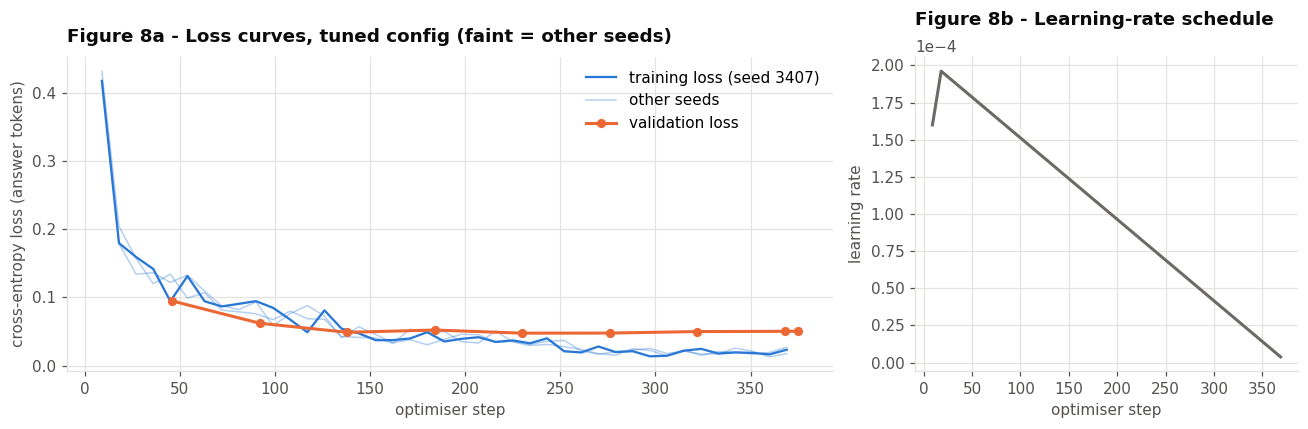

In [ ]:
log = pd.DataFrame(main["log"])
tr_log = log.dropna(subset=["loss"]) if "loss" in log else pd.DataFrame()
ev_log = log.dropna(subset=["eval_loss"]) if "eval_loss" in log else pd.DataFrame()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2, 1]})
for s, rec in zip(SEEDS, R["seeds"]):
    lg = pd.DataFrame(rec["log"])
    if "loss" in lg:
        lg = lg.dropna(subset=["loss"])
        lab = f"training loss (seed {s})" if rec is main else ("other seeds" if s == SEEDS[1] else None)
        ax1.plot(lg["step"], lg["loss"], color=FT_C, alpha=1 if rec is main else 0.35,
                 linewidth=1.5 if rec is main else 1, label=lab)
if len(ev_log):
    ax1.plot(ev_log["step"], ev_log["eval_loss"], color=ZERO_C, marker="o", markersize=5, label="validation loss")
ax1.set_xlabel("optimiser step"); ax1.set_ylabel("cross-entropy loss (answer tokens)"); ax1.legend()
ax1.set_title("Figure 8a - Loss curves, tuned config (faint = other seeds)")
if "learning_rate" in tr_log:
    ax2.plot(tr_log["step"], tr_log["learning_rate"], color=GOLD_C)
ax2.set_xlabel("optimiser step"); ax2.set_ylabel("learning rate"); ax2.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
ax2.set_title("Figure 8b - Learning-rate schedule")
savefig(fig, "fig08_training_curves", "Training/validation loss and learning-rate schedule")

In [ ]:
def row_for(label, rec, name="A_test"):
    s = rec["eval"][name]["summary"]
    return {"Model": label, **{n: f"{s[m][0]:.1f} [{s[m][1]:.1f}, {s[m][2]:.1f}]" for m, n in METRICS}}

models = [("Zero-shot", R["zero"])] + ([("3-shot prompting", R["few"])] if "few" in R else [])
if R["default"] is not main:
    models.append((f"LoRA default config", R["default"]))
models.append((f"LoRA tuned config (seed {SEEDS[0]})", main))
t5 = pd.DataFrame([row_for(l, r) for l, r in models])
seed_ex = {m: [r["eval"]["A_test"]["summary"][m][0] for r in R["seeds"]] for m, _ in METRICS}
t5.loc[len(t5)] = {"Model": f"LoRA tuned, mean ± SD over {len(SEEDS)} seeds",
                   **{n: f"{np.mean(seed_ex[m]):.1f} ± {np.std(seed_ex[m], ddof=1):.1f}" for m, n in METRICS}}
t5["B-test EX"] = [f"{ex_of(r, 'B_test'):.1f}" for _, r in models] + [
    f"{np.mean([ex_of(r, 'B_test') for r in R['seeds']]):.1f} ± {np.std([ex_of(r, 'B_test') for r in R['seeds']], ddof=1):.1f}"]
t5["s / example"] = [f"{r['eval']['A_test']['secs_per_example']:.2f}" for _, r in models] + [""]
print(f"Table 5 - Test results on A-test (n = {len(test_A)}), % with 95% bootstrap CI; last column: B-test EX")
display(t5.set_index("Model"))

tests = []
for s, rec in zip(SEEDS, R["seeds"]):
    n01, n10, p = mcnemar(zero_df["correct"], rec["eval"]["A_test"]["df"]["correct"])
    tests.append({"comparison": f"tuned (seed {s}) vs zero-shot", "fixed": n01, "broken": n10, "p-value": p})
if few_df is not None:
    n01, n10, p = mcnemar(few_df["correct"], ft_df["correct"])
    tests.append({"comparison": "tuned vs 3-shot", "fixed": n01, "broken": n10, "p-value": p})
if R["default"] is not main:
    n01, n10, p = mcnemar(R["default"]["eval"]["A_test"]["df"]["correct"], ft_df["correct"])
    tests.append({"comparison": "tuned vs default LoRA config", "fixed": n01, "broken": n10, "p-value": p})
tests = pd.DataFrame(tests)
tests["significant (alpha=0.05)"] = tests["p-value"] < 0.05
print("Table 6 - McNemar exact tests on A-test (fixed = only the second model correct)")
display(tests.assign(**{"p-value": tests["p-value"].map(lambda p: f"{p:.2e}")}))
p_mcnemar = tests.iloc[0]["p-value"]; n01, n10 = tests.iloc[0]["fixed"], tests.iloc[0]["broken"]

Table 5 - Test results on A-test (n = 200), % with 95% bootstrap CI; last column: B-test EX


,Execution Accuracy,Exact Match,Valid SQL,Token F1,Format compliance,B-test EX,s / example
Model,,,,,,,
Zero-shot,"34.0 [27.3, 40.7]","33.0 [27.0, 39.5]","90.5 [86.5, 94.5]","85.8 [83.7, 88.0]","100.0 [100.0, 100.0]",41.0,0.25
3-shot prompting,"26.3 [20.1, 32.5]","30.0 [24.0, 36.5]","90.0 [85.5, 94.0]","85.5 [83.4, 87.6]","100.0 [100.0, 100.0]",41.0,0.38
LoRA default config,"79.4 [73.7, 84.5]","68.0 [61.5, 74.5]","94.5 [91.5, 97.5]","95.8 [94.7, 96.9]","100.0 [100.0, 100.0]",24.0,0.26
LoRA tuned config (seed 3407),"80.9 [75.3, 86.1]","74.5 [68.5, 80.5]","95.0 [92.0, 98.0]","97.1 [96.3, 97.9]","100.0 [100.0, 100.0]",23.0,0.36
"LoRA tuned, mean ± SD over 3 seeds",81.6 ± 1.2,74.3 ± 0.3,95.3 ± 1.0,96.9 ± 0.3,100.0 ± 0.0,24.3 ± 1.5,


Table 6 - McNemar exact tests on A-test (fixed = only the second model correct)


,comparison,fixed,broken,p-value,significant (alpha=0.05)
0,tuned (seed 3407) vs zero-shot,94,3,1.92e-24,True
1,tuned (seed 42) vs zero-shot,95,2,6.00e-26,True
2,tuned (seed 1234) vs zero-shot,97,1,6.25e-28,True
3,tuned vs 3-shot,109,3,9.02e-29,True
4,tuned vs default LoRA config,8,5,5.81e-01,False


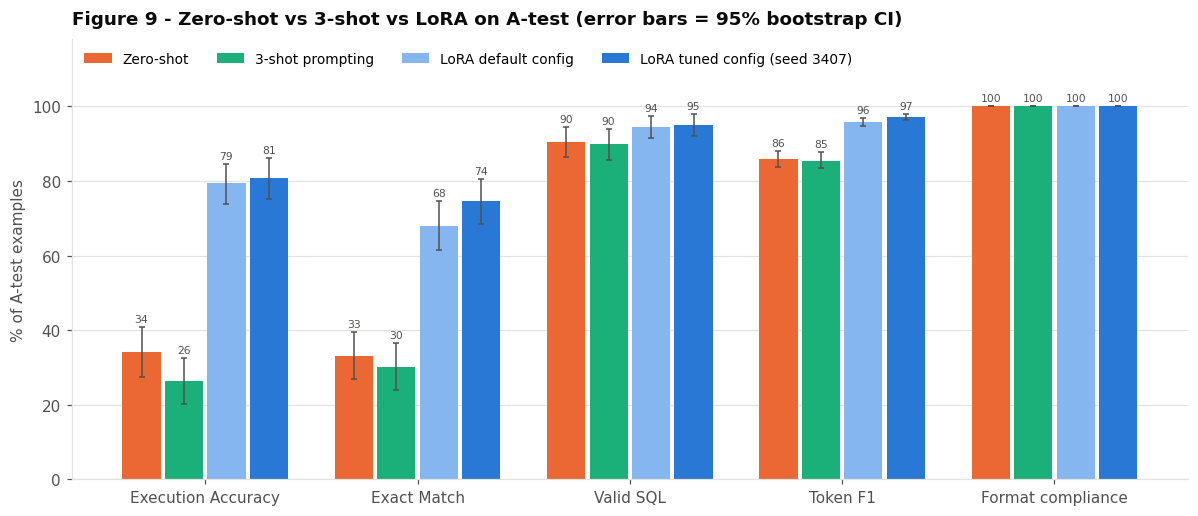

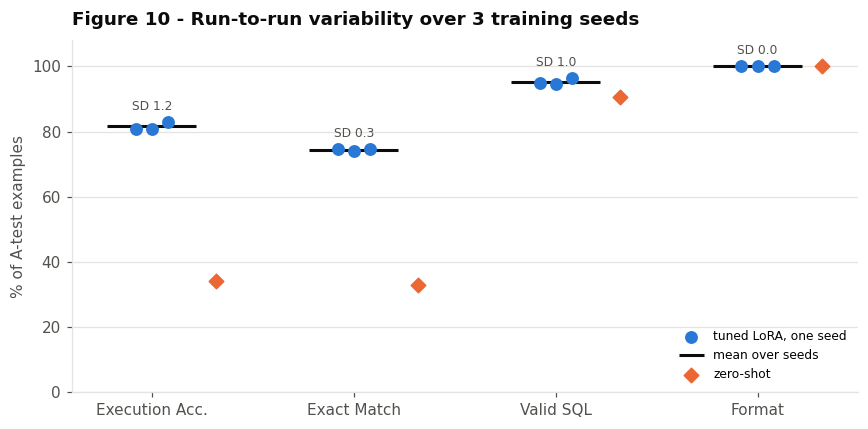

In [ ]:
colors = {"Zero-shot": ZERO_C, "3-shot prompting": FEW_C, "LoRA default config": DEF_C}
fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(METRICS)); k = len(models); w = 0.8 / k
for i, (lab, rec) in enumerate(models):
    s = rec["eval"]["A_test"]["summary"]
    vals = np.array([s[m][0] for m, _ in METRICS])
    err = np.array([[s[m][0] - s[m][1], s[m][2] - s[m][0]] for m, _ in METRICS]).T
    bars = ax.bar(x + (i - (k - 1) / 2) * w, vals, w - 0.02, color=colors.get(lab, FT_C), label=lab, yerr=err,
                  error_kw={"ecolor": INK2, "elinewidth": 1, "capsize": 2})
    for b, v, hi in zip(bars, vals, vals + err[1]):
        ax.annotate(f"{v:.0f}", (b.get_x() + b.get_width() / 2, hi), xytext=(0, 2), textcoords="offset points",
                    ha="center", va="bottom", fontsize=7, color=INK2)
ax.set_xticks(x); ax.set_xticklabels([n for _, n in METRICS]); ax.set_ylim(0, 118)
ax.set_ylabel("% of A-test examples"); ax.legend(loc="upper left", ncol=k, fontsize=9); ax.grid(axis="x", visible=False)
ax.set_title("Figure 9 - Zero-shot vs 3-shot vs LoRA on A-test (error bars = 95% bootstrap CI)")
savefig(fig, "fig09_main_results", "Main results on A-test with 95% CIs")

fig, ax = plt.subplots(figsize=(8, 4))
show_m = [("ex", "Execution Acc."), ("em", "Exact Match"), ("valid", "Valid SQL"), ("format_ok", "Format")]
for j, (m, n) in enumerate(show_m):
    vals = seed_ex[m]
    ax.scatter(np.full(len(vals), j) + np.linspace(-0.08, 0.08, len(vals)), vals, color=FT_C, s=55, zorder=3,
               label="tuned LoRA, one seed" if j == 0 else None)
    ax.hlines(np.mean(vals), j - 0.22, j + 0.22, color=INK, linewidth=2, label="mean over seeds" if j == 0 else None)
    ax.scatter([j + 0.32], [R["zero"]["eval"]["A_test"]["summary"][m][0]], marker="D", color=ZERO_C, s=45,
               label="zero-shot" if j == 0 else None)
    ax.annotate(f"SD {np.std(vals, ddof=1):.1f}", (j, max(vals)), xytext=(0, 8), textcoords="offset points",
                ha="center", fontsize=8, color=INK2)
ax.set_xticks(range(len(show_m))); ax.set_xticklabels([n for _, n in show_m]); ax.set_ylim(0, 108)
ax.set_ylabel("% of A-test examples"); ax.legend(loc="lower right", fontsize=8); ax.grid(axis="x", visible=False)
ax.set_title(f"Figure 10 - Run-to-run variability over {len(SEEDS)} training seeds")
savefig(fig, "fig10_seed_variability", "Seed variability of the tuned configuration")

## 8. Where does fine-tuning help? Breakdowns and error analysis (A-test, tuned model's first seed vs baselines)

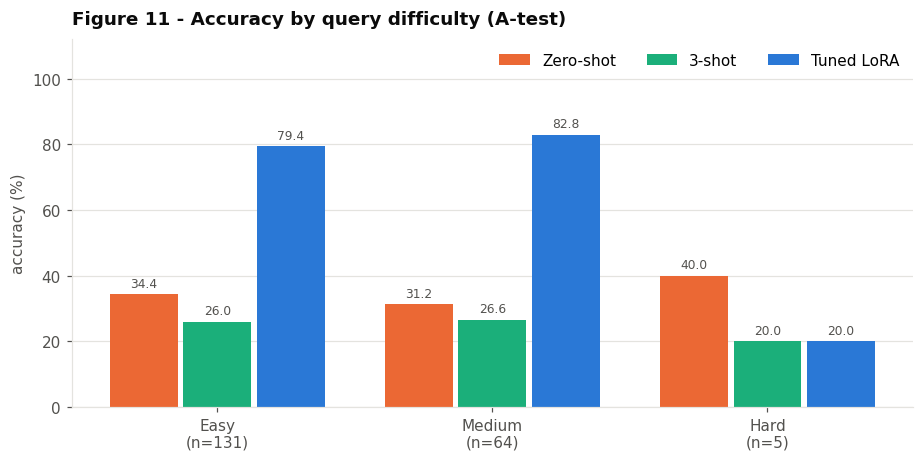

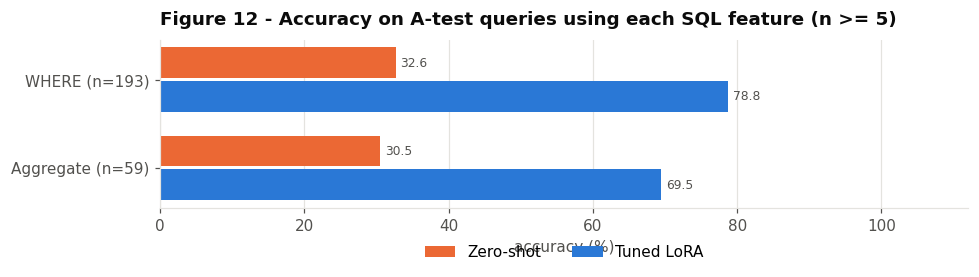

,n,base,fine-tuned,Δ (pp)
feature,,,,
Aggregate,59,30.5,69.5,39.0
WHERE,193,32.6,78.8,46.1


In [ ]:
comp = [("Zero-shot", zero_df, ZERO_C)] + ([("3-shot", few_df, FEW_C)] if few_df is not None else []) + [("Tuned LoRA", ft_df, FT_C)]
diff_n = ft_df["difficulty"].value_counts().reindex(DIFF_ORDER).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(8.5, 4.3))
k = len(comp); w = 0.8 / k
for i, (lab, df, c) in enumerate(comp):
    acc = df.groupby("difficulty")["correct"].mean().reindex(DIFF_ORDER).fillna(0) * 100
    label_bars(ax, ax.bar(np.arange(3) + (i - (k - 1) / 2) * w, acc, w - 0.02, color=c, label=lab))
ax.set_xticks(range(3)); ax.set_xticklabels([f"{d}\n(n={diff_n[d]})" for d in DIFF_ORDER]); ax.set_ylim(0, 112)
ax.set_ylabel("accuracy (%)"); ax.legend(ncol=k, loc="upper right"); ax.grid(axis="x", visible=False)
ax.set_title("Figure 11 - Accuracy by query difficulty (A-test)")
savefig(fig, "fig11_by_difficulty", "Accuracy by query difficulty")
b_d = zero_df.groupby("difficulty")["correct"].mean().reindex(DIFF_ORDER) * 100
f_d = ft_df.groupby("difficulty")["correct"].mean().reindex(DIFF_ORDER) * 100

feat_rows = []
for kf in FEATURES:
    m = ft_df[f"has_{kf}"].astype(bool)
    if m.sum() >= 5:
        feat_rows.append({"feature": kf, "n": int(m.sum()), "base": zero_df.loc[m, "correct"].mean() * 100,
                          "fine-tuned": ft_df.loc[m, "correct"].mean() * 100})
by_feat = pd.DataFrame(feat_rows).sort_values("fine-tuned")
by_feat["Δ (pp)"] = by_feat["fine-tuned"] - by_feat["base"]
fig, ax = plt.subplots(figsize=(9, 0.55 * len(by_feat) + 1.6))
y = np.arange(len(by_feat)); h = 0.38
label_bars(ax, ax.barh(y + h / 2, by_feat["base"], h - 0.03, color=ZERO_C, label="Zero-shot"), horizontal=True)
label_bars(ax, ax.barh(y - h / 2, by_feat["fine-tuned"], h - 0.03, color=FT_C, label="Tuned LoRA"), horizontal=True)
ax.set_yticks(y); ax.set_yticklabels([f"{f} (n={n})" for f, n in zip(by_feat.feature, by_feat.n)])
ax.set_xlim(0, 112); ax.set_xlabel("accuracy (%)"); ax.grid(axis="y", visible=False)
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.14))
ax.set_title("Figure 12 - Accuracy on A-test queries using each SQL feature (n >= 5)")
savefig(fig, "fig12_by_feature", "Accuracy by SQL feature")
display(by_feat.round(1).set_index("feature"))

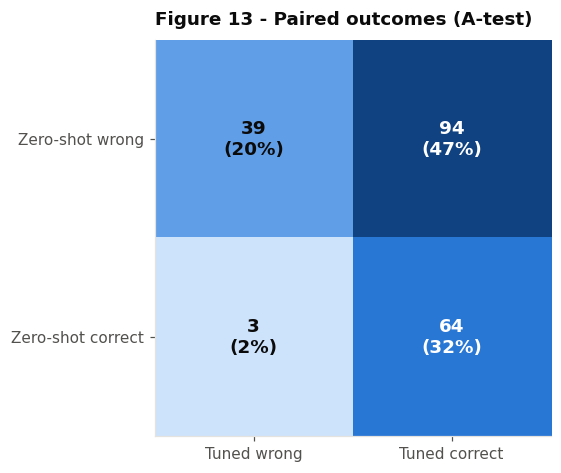

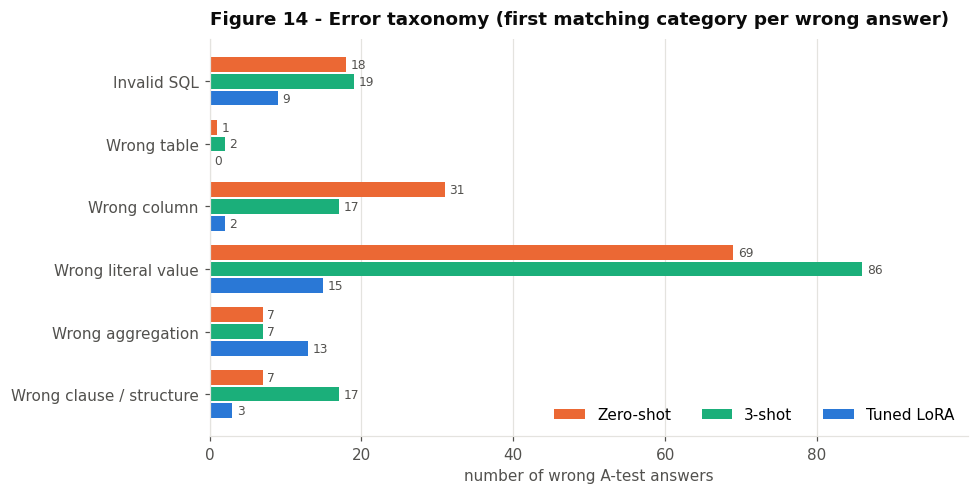

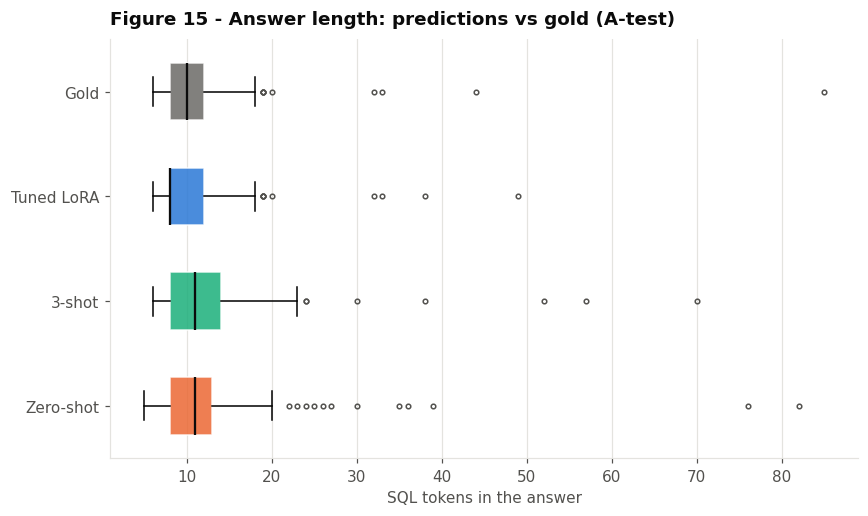

In [ ]:
b_ok, f_ok = zero_df["correct"].values.astype(bool), ft_df["correct"].values.astype(bool)
cont = pd.crosstab(pd.Series(b_ok, name="Zero-shot"), pd.Series(f_ok, name="Tuned")).reindex(
    index=[False, True], columns=[False, True], fill_value=0)
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.imshow(cont.values, cmap=BLUES)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Tuned wrong", "Tuned correct"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Zero-shot wrong", "Zero-shot correct"]); ax.grid(False)
vmax = cont.values.max()
for i in range(2):
    for j in range(2):
        v = cont.values[i, j]
        ax.text(j, i, f"{v}\n({100 * v / cont.values.sum():.0f}%)", ha="center", va="center", fontsize=12,
                color="white" if v > vmax * 0.55 else INK, fontweight="bold")
ax.set_title("Figure 13 - Paired outcomes (A-test)")
savefig(fig, "fig13_contingency", "Paired zero-shot vs tuned outcomes")

err_cols = [(lab, df["error_type"].value_counts().reindex(ERROR_ORDER).fillna(0), c) for lab, df, c in comp]
fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(ERROR_ORDER))[::-1]; k = len(err_cols); h = 0.8 / k
for i, (lab, e, c) in enumerate(err_cols):
    label_bars(ax, ax.barh(y + ((k - 1) / 2 - i) * h, e.values, h - 0.03, color=c, label=lab), "{:.0f}", True)
ax.set_yticks(y); ax.set_yticklabels(ERROR_ORDER); ax.set_xlabel("number of wrong A-test answers")
ax.set_xlim(0, max(e.max() for _, e, _ in err_cols) * 1.15 + 1)
ax.legend(ncol=k, loc="lower right"); ax.grid(axis="y", visible=False)
ax.set_title("Figure 14 - Error taxonomy (first matching category per wrong answer)")
savefig(fig, "fig14_error_taxonomy", "Error taxonomy")
err_f = err_cols[-1][1]

fig, ax = plt.subplots(figsize=(8, 3.6 + 0.4 * len(comp)))
golds_A = [r["answer"] for r in test_A]
data = [df["pred_tokens"] for _, df, _ in comp] + [[len(sql_tokens(g)) for g in golds_A]]
bp = ax.boxplot(data, vert=False, patch_artist=True, widths=0.55,
                medianprops={"color": INK, "linewidth": 1.5}, flierprops={"markersize": 3, "markeredgecolor": INK2})
for patch, c in zip(bp["boxes"], [c for _, _, c in comp] + [GOLD_C]):
    patch.set_facecolor(c); patch.set_alpha(0.85); patch.set_edgecolor("white")
ax.set_yticklabels([lab for lab, _, _ in comp] + ["Gold"]); ax.set_xlabel("SQL tokens in the answer"); ax.grid(axis="y", visible=False)
ax.set_title("Figure 15 - Answer length: predictions vs gold (A-test)")
savefig(fig, "fig15_output_length", "Answer length distributions")

In [ ]:
pd.set_option("display.max_colwidth", 120)
cmp = pd.DataFrame({"question": zero_df.question, "gold": zero_df.gold, "zero_pred": zero_df.pred,
                    "ft_pred": ft_df.pred, "zero_ok": b_ok, "ft_ok": f_ok, "ft_error": ft_df.error_type,
                    "difficulty": ft_df.difficulty})
print("Table 7a - Fixed by fine-tuning")
display(cmp[~cmp.zero_ok & cmp.ft_ok][["question", "gold", "zero_pred", "ft_pred"]].head(5))
print("Table 7b - Still wrong after fine-tuning")
display(cmp[~cmp.ft_ok][["question", "gold", "ft_pred", "ft_error", "difficulty"]].head(6))
print("Table 7c - Correct by execution but not by exact match (equivalent SQL written differently)")
display(cmp[(ft_df.ex == 1) & ~ft_df.em.astype(bool)][["question", "gold", "ft_pred"]].head(4))

Table 7a - Fixed by fine-tuning


,question,gold,zero_pred,ft_pred
0,Name the least game for record of 5-1-3,"SELECT MIN(game) FROM table_name_93 WHERE record = ""5-1-3""",SELECT * FROM table_name_93 WHERE game = 5 AND record = 1 AND record = 3,"SELECT MIN(game) FROM table_name_93 WHERE record = ""5-1-3"""
2,What was the attendance record for Leicester City?,"SELECT attendance FROM table_name_17 WHERE home_team = ""leicester city""",SELECT * FROM table_name_17 WHERE home_team = 'Leicester City',"SELECT attendance FROM table_name_17 WHERE home_team = ""leicester city"""
3,Which one of the tournaments had a QF in 1996?,"SELECT tournament FROM table_name_42 WHERE 1996 = ""qf""",SELECT tournament FROM table_name_42 WHERE tournament = '1996',"SELECT tournament FROM table_name_42 WHERE 1996 = ""qf"""
5,"When Bunky Henry placed t8, what was his To par?","SELECT to_par FROM table_name_75 WHERE place = ""t8"" AND player = ""bunky henry""",SELECT to_par FROM table_name_75 WHERE place = 't8' AND player = 'Bunky Henry',"SELECT to_par FROM table_name_75 WHERE place = ""t8"" AND player = ""bunky henry"""
7,What was the score on April 22?,"SELECT score FROM table_name_17 WHERE date = ""april 22""",SELECT score FROM table_name_17 WHERE date = 'April 22',"SELECT score FROM table_name_17 WHERE date = ""april 22"""


Table 7b - Still wrong after fine-tuning


,question,gold,ft_pred,ft_error,difficulty
1,What is the zip code of staff with first name as Janessa and last name as Sawayn lived?,SELECT T1.zip_postcode FROM Addresses AS T1 JOIN Staff AS T2 ON T1.address_id = T2.staff_address_id WHERE T2.first_n...,SELECT T1.zip_postcode FROM Staff AS T1 JOIN Addresses AS T2 ON T1.staff_address_id = T2.address_id WHERE T1.first_n...,Invalid SQL,Hard
8,Which year's label was label?,"SELECT year FROM table_name_57 WHERE ""label"" = ""label""","SELECT year FROM table_name_57 WHERE label = ""label""",Invalid SQL,Easy
9,What year has an issue price of $697.95?,"SELECT COUNT(year) FROM table_name_9 WHERE issue_price = ""$697.95""","SELECT year FROM table_name_9 WHERE issue_price = ""$697.95""",Wrong aggregation,Easy
11,What was the pick for the game at the College of Kentucky with the team Washington Capitols?,"SELECT pick FROM table_name_56 WHERE college = ""kentucky"" AND team = ""washington capitols""","SELECT COUNT(pick) FROM table_name_56 WHERE college = ""kentucky"" AND team = ""washington capitols""",Wrong aggregation,Medium
13,what tournament has 2000 of 3r?,"SELECT tournament FROM table_name_35 WHERE 2000 = ""3r""",SELECT tournament FROM table_name_35 WHERE 3r = 2000,Invalid SQL,Easy
15,What was the attendance on 31 January 2009 when the opponent was Airdrie United?,"SELECT AVG(attendance) FROM table_name_33 WHERE opponent = ""airdrie united"" AND date = ""31 january 2009""","SELECT AVG(attendance) FROM table_name_33 WHERE opponent = ""airrie united"" AND date = ""31 january 2009""",Wrong literal value,Medium


Table 7c - Correct by execution but not by exact match (equivalent SQL written differently)


,question,gold,ft_pred
20,What is the lowest enrolled school that was founded in 1992 and joined a conference before 1998?,"SELECT MIN(enrollment) FROM table_name_19 WHERE founded = ""1992"" AND joined_conference < 1998",SELECT MIN(enrollment) FROM table_name_19 WHERE founded = 1992 AND joined_conference < 1998
28,Who built the ship that is 42.8 m long and was delivered in 2007?,"SELECT builder FROM table_name_83 WHERE length = ""42.8 m"" AND delivery = 2007","SELECT builder FROM table_name_83 WHERE length = ""42.8 m"" AND delivery = ""2007"""
36,"Which Seats have a Share of votes of 18%, and a Share of seats of 3%, and a General election larger than 1992?","SELECT MAX(seats) FROM table_name_62 WHERE share_of_votes = ""18%"" AND share_of_seats = ""3%"" AND general_election > 1992","SELECT SUM(seats) FROM table_name_62 WHERE share_of_votes = ""18%"" AND share_of_seats = ""3%"" AND general_election > 1992"
58,What GEO ID has a longitude of -102.693028?,SELECT geo_id FROM table_name_83 WHERE longitude = -102.693028,"SELECT geo_id FROM table_name_83 WHERE longitude = ""-102.693028"""


## 9. Stage 3 — Cross-dataset generalisation

Does a model trained on one dataset work on another? We train the tuned configuration on A, on B, and on a 50/50 mix (A+B) with the same total number of examples, and test each on both A-test and B-test.

[retrain] ftB_r16_a1_lr0.0002_e3_all_s3407: results are cached but the adapter was not saved yet - retraining to save it
==((====))==  Unsloth 2026.10.8: Fast Qwen3_5 patching. Transformers: 5.16.1.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for qwen3_5 won't work! Using float32.


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

Unsloth: Explicit target_modules are constrained by the finetune_(vision|language|attention|mlp) filters; adapters attach only where both select.
Unsloth: Switching to float32 training since model cannot work with float16


Unsloth: Tokenizing ["text"]:   0%|          | 0/2000 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"]:   0%|          | 0/100 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


... (24 outputs left out)

[saved adapter] /kaggle/working/adapters/ftAB_r16_a1_lr0.0002_e3_all_s3407


generating:   0%|          | 0/13 [00:00<?, ?it/s]

generating:   0%|          | 0/13 [00:00<?, ?it/s]

[done] ftAB_r16_a1_lr0.0002_e3_all_s3407: A_test EX=79.4 | B_test EX=57.0 (18.4 min)


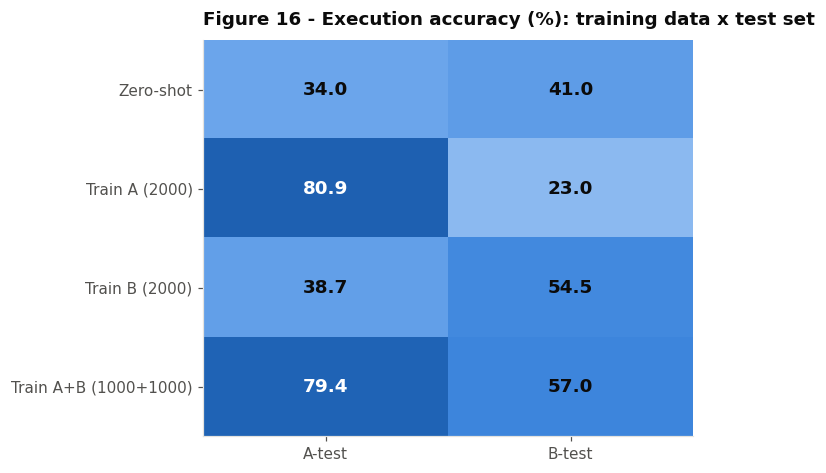

Table 8 - Cross-dataset execution accuracy (%)


,A-test,B-test
Zero-shot,34.0,41.0
Train A (2000),80.9,23.0
Train B (2000),38.7,54.5
Train A+B (1000+1000),79.4,57.0


In [ ]:
grid = {"Zero-shot": R["zero"], f"Train A ({N_TRAIN})": main}
if RUN_DATASETS:
    half = N_TRAIN // 2
    grid[f"Train B ({N_TRAIN})"] = experiment(f"ftB_{hp_key(BEST_HP)}_s{SEED}", train_rows=train_B, hp=BEST_HP,
                                              seed=SEED, evals=EVALS, val_rows=val_B, save_adapter=True)
    mix = train_A[:half] + train_B[:half]
    random.Random(SEED).shuffle(mix)
    grid[f"Train A+B ({half}+{half})"] = experiment(f"ftAB_{hp_key(BEST_HP)}_s{SEED}", train_rows=mix, hp=BEST_HP,
                                                    seed=SEED, evals=EVALS, val_rows=val_A[:N_VAL // 2] + val_B[:N_VAL // 2],
                                                    save_adapter=True)
grid_df = pd.DataFrame({k: {"A-test": ex_of(r, "A_test"), "B-test": ex_of(r, "B_test")} for k, r in grid.items()}).T
fig, ax = plt.subplots(figsize=(6.5, 0.7 * len(grid_df) + 1.6))
ax.imshow(grid_df.values, cmap=BLUES, vmin=0, vmax=100, aspect="auto")
for i in range(grid_df.shape[0]):
    for j in range(grid_df.shape[1]):
        v = grid_df.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=12, fontweight="bold",
                color="white" if v > 60 else INK)
ax.set_xticks(range(grid_df.shape[1])); ax.set_xticklabels(grid_df.columns)
ax.set_yticks(range(grid_df.shape[0])); ax.set_yticklabels(grid_df.index); ax.grid(False)
ax.set_title("Figure 16 - Execution accuracy (%): training data x test set")
savefig(fig, "fig16_cross_dataset", "Cross-dataset execution accuracy")
print("Table 8 - Cross-dataset execution accuracy (%)"); display(grid_df.round(1))

## 10. Stage 4 — Model scaling

Is it better to fine-tune a small model or to use a bigger one? We evaluate Qwen3.5-**2B** zero-shot and fine-tuned with the **same** selected configuration and training data. *Caveat:* the configuration was tuned for 0.8B; larger models might prefer, e.g., a lower learning rate.

**Hardware limit.** The T4 has no bfloat16 support and Qwen3.5 is unstable in float16, so Unsloth runs it in **float32** (4 bytes per weight). Weights alone then need ≈ 3 GB (0.8B), ≈ 9 GB (2B) and ≈ 16 GB (4B) — the 4B model does not fit the T4's 14.5 GB. Setting `RUN_4B_4BIT = True` adds Qwen3.5-4B loaded in **4-bit** (QLoRA); it fits, but quantisation changes the model, so compare it with the others only with that caveat.

[cached] zero_2B
[retrain] ftA_2B_r16_a1_lr0.0002_e3_all_s3407: results are cached but the adapter was not saved yet - retraining to save it
==((====))==  Unsloth 2026.10.8: Fast Qwen3_5 patching. Transformers: 5.16.1.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for qwen3_5 won't work! Using float32.


/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:299: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Loading weights:   0%|          | 0/617 [00:00<?, ?it/s]

Unsloth: Explicit target_modules are constrained by the finetune_(vision|language|attention|mlp) filters; adapters attach only where both select.
Unsloth: Switching to float32 training since model cannot work with float16


Unsloth: Tokenizing ["text"]:   0%|          | 0/2000 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"]:   0%|          | 0/100 [00:00<?, ? examples/s]

... (10 outputs left out)

generating:   0%|          | 0/13 [00:00<?, ?it/s]

generating:   0%|          | 0/13 [00:00<?, ?it/s]

[done] ftA_2B_r16_a1_lr0.0002_e3_all_s3407: A_test EX=83.0 | B_test EX=32.5 (19.0 min)
Table 9 - Model scaling


,params (M),trainable (M),zero-shot EX A,fine-tuned EX A,zero-shot EX B,fine-tuned EX B,train min,peak VRAM (GB),s / example (ft)
model,,,,,,,,,
Qwen3.5-0.8B,859.38,6.39,34.02,80.93,41.0,23.0,15.21,2.45,0.36
Qwen3.5-2B,2224.15,10.91,37.11,82.99,50.5,32.5,15.61,6.74,0.30


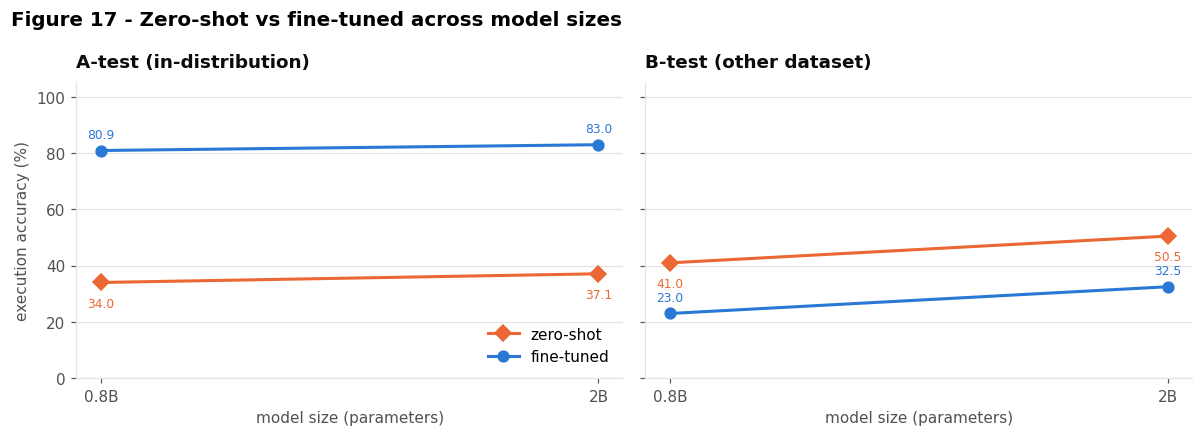

In [ ]:
scale = [("0.8B", R["zero"], main)]
if RUN_SCALING:
    todo = [(size, name, False) for size, name in SCALING_MODELS.items()]
    if RUN_4B_4BIT:
        todo.append(("4B-4bit", MODEL_4B, True))
    for size, name, fb in todo:
        try:
            z = experiment(f"zero_{size}", model_name=name, size_tag=size, evals=EVALS, four_bit=fb)
            f = experiment(f"ftA_{size}_{hp_key(BEST_HP)}_s{SEED}", model_name=name, size_tag=size, train_rows=train_A,
                           hp=BEST_HP, seed=SEED, evals=EVALS, val_rows=val_A, four_bit=fb, save_adapter=True)
            scale.append((size, z, f))
        except RuntimeError as e:
            if not is_oom(e):
                raise
            print(f"SKIPPED {size}: out of GPU memory on this hardware ({str(e)[:90]}...)")
scale_df = pd.DataFrame([{
    "model": f"Qwen3.5-{s}", "params (M)": f["total_params_M"] if f["train"] is None else f["train"]["total_params_M"],
    "trainable (M)": f["train"]["trainable_params_M"], "zero-shot EX A": ex_of(z, "A_test"), "fine-tuned EX A": ex_of(f, "A_test"),
    "zero-shot EX B": ex_of(z, "B_test"), "fine-tuned EX B": ex_of(f, "B_test"),
    "train min": f["train"]["train_time_min"], "peak VRAM (GB)": f["train"]["peak_vram_gb"],
    "s / example (ft)": f["eval"]["A_test"]["secs_per_example"]} for s, z, f in scale]).set_index("model")
print("Table 9 - Model scaling"); display(scale_df.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
xs = np.arange(len(scale))
for ax, col, title in zip(axes, ["A", "B"], ["A-test (in-distribution)", "B-test (other dataset)"]):
    for kind, c, mk in [("zero-shot", ZERO_C, "D"), ("fine-tuned", FT_C, "o")]:
        v = scale_df[f"{kind} EX {col}"].values
        ax.plot(xs, v, color=c, marker=mk, markersize=7, label=kind)
        for xi, vi in zip(xs, v):
            ax.annotate(f"{vi:.1f}", (xi, vi), xytext=(0, 8 if kind == "fine-tuned" else -16), textcoords="offset points",
                        ha="center", fontsize=8, color=c)
    ax.set_xticks(xs); ax.set_xticklabels([f"{s}" for s, _, _ in scale]); ax.set_xlabel("model size (parameters)")
    ax.set_ylim(0, 105); ax.set_title(title); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("execution accuracy (%)"); axes[0].legend(loc="lower right")
fig.suptitle("Figure 17 - Zero-shot vs fine-tuned across model sizes", x=0.01, ha="left", fontweight="bold", fontsize=13)
savefig(fig, "fig17_scaling", "Model scaling")

## 11. Stage 5 — Training-set-size ablation

How much data does a 0.8B model need? Nested subsets of A-train (each contains the smaller ones), tuned configuration, evaluated on A-test. Size 0 is the zero-shot model; the largest size is the main run.

[cached] ftA_n250_r16_a1_lr0.0002_e3_all_s3407
[cached] ftA_n500_r16_a1_lr0.0002_e3_all_s3407
[cached] ftA_n1000_r16_a1_lr0.0002_e3_all_s3407


,Execution Accuracy,Exact Match,Valid SQL,Token F1,Format compliance
train_examples,,,,,
0,34.0,33.0,90.5,85.8,100.0
250,60.8,61.0,92.5,94.1,100.0
500,76.8,65.5,94.0,95.5,100.0
1000,80.9,70.5,96.0,96.6,100.0
2000,80.9,74.5,95.0,97.1,100.0


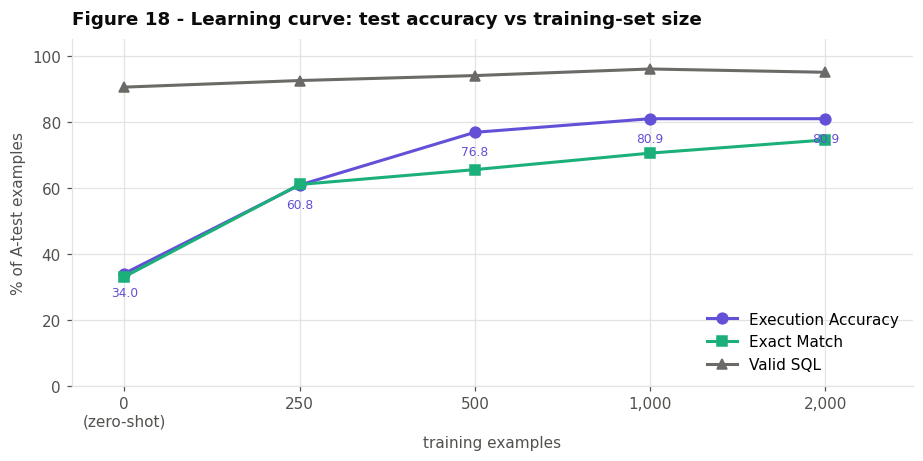

In [ ]:
abl = [{"train_examples": 0, **{m: R["zero"]["eval"]["A_test"]["summary"][m][0] for m, _ in METRICS}},
       {"train_examples": N_TRAIN, **{m: main["eval"]["A_test"]["summary"][m][0] for m, _ in METRICS}}]
if RUN_SIZE_ABLATION:
    for n in ABLATION_SIZES:
        rec = experiment(f"ftA_n{n}_{hp_key(BEST_HP)}_s{SEED}", train_rows=train_A[:n], hp=BEST_HP, seed=SEED,
                         evals=("A_test",))
        abl.append({"train_examples": n, **{m: rec["eval"]["A_test"]["summary"][m][0] for m, _ in METRICS}})
abl_df = pd.DataFrame(abl).sort_values("train_examples").reset_index(drop=True)
display(abl_df.rename(columns=dict(METRICS)).round(1).set_index("train_examples"))

fig, ax = plt.subplots(figsize=(8.5, 4.3))
xs = np.arange(len(abl_df))
for m, name, col, mk in [("ex", "Execution Accuracy", VIOLET, "o"), ("em", "Exact Match", ACCENT, "s"),
                         ("valid", "Valid SQL", GOLD_C, "^")]:
    ax.plot(xs, abl_df[m], marker=mk, markersize=7, color=col, label=name)
for xi, v in zip(xs, abl_df["ex"]):
    ax.annotate(f"{v:.1f}", (xi, v), xytext=(0, -15), textcoords="offset points", ha="center", fontsize=8, color=VIOLET)
ax.set_xticks(xs); ax.set_xticklabels([("0\n(zero-shot)" if n == 0 else f"{n:,}") for n in abl_df.train_examples])
ax.set_xlabel("training examples"); ax.set_ylabel("% of A-test examples"); ax.set_ylim(0, 105)
ax.legend(loc="lower right"); ax.set_xlim(-0.3, len(xs) - 0.5)
ax.set_title("Figure 18 - Learning curve: test accuracy vs training-set size")
savefig(fig, "fig18_size_ablation", "Accuracy vs training-set size")

## 12. Results & Discussion

Generated from the measured numbers, so it always matches the tables and figures. Use it as the basis of the report.

In [ ]:
def pp(x): return f"{x:+.1f} pp"
Z, F = R["zero"]["eval"]["A_test"]["summary"], main["eval"]["A_test"]["summary"]
ex_mean, ex_sd = np.mean(seed_ex["ex"]), np.std(seed_ex["ex"], ddof=1)
paras = []

paras.append(
    f"**Main finding.** LoRA fine-tuning of Qwen3.5-0.8B on {N_TRAIN:,} examples raised execution accuracy on A-test "
    f"from **{Z['ex'][0]:.1f}%** (zero-shot, 95% CI {Z['ex'][1]:.1f}–{Z['ex'][2]:.1f}) to **{ex_mean:.1f}% ± {ex_sd:.1f}** "
    f"(mean ± SD over {len(SEEDS)} seeds; first-seed CI {F['ex'][1]:.1f}–{F['ex'][2]:.1f}), a gain of **{pp(ex_mean - Z['ex'][0])}** "
    f"(Table 5, Figure 9). McNemar tests against zero-shot give p = "
    + ", ".join(f"{p:.1e}" for p in tests[tests.comparison.str.contains('zero')]["p-value"])
    + f" for the {len(SEEDS)} seeds, so the improvement is "
    + ("**significant for every seed**." if (tests[tests.comparison.str.contains('zero')]["p-value"] < 0.05).all()
       else "**not significant for every seed**.")
    + f" Format compliance went from {Z['format_ok'][0]:.1f}% to {F['format_ok'][0]:.1f}% and valid-SQL rate from "
    f"{Z['valid'][0]:.1f}% to {F['valid'][0]:.1f}%.")

if "few" in R:
    Fw = R["few"]["eval"]["A_test"]["summary"]
    r_few = tests[tests.comparison == "tuned vs 3-shot"].iloc[0]
    paras.append(
        f"**Is fine-tuning necessary?** 3-shot prompting reached {Fw['ex'][0]:.1f}% EX "
        f"({pp(Fw['ex'][0] - Z['ex'][0])} over zero-shot) without any training, while the tuned LoRA model scored "
        f"{pp(F['ex'][0] - Fw['ex'][0])} above 3-shot (McNemar p = {r_few['p-value']:.1e}). "
        + ("Prompting closes part of the gap, but fine-tuning is clearly better." if r_few["p-value"] < 0.05 and F['ex'][0] > Fw['ex'][0]
           else "The difference between prompting and fine-tuning is not significant here."))

if tune_rows:
    top_f = sens_df.index[0]; low_f = sens_df.index[-1]
    paras.append(
        f"**Hyperparameters (Stage 1).** On the tuning set the most sensitive hyperparameter was **{HP_LABELS[top_f]}** "
        f"(EX range {sens_df.iloc[0]:.1f} pp across its values) and the least sensitive was **{HP_LABELS[low_f]}** "
        f"({sens_df.iloc[-1]:.1f} pp) (Figure 7, Table 3). LoRA rank changed tuning EX by {sens.get('lora_r', float('nan')):.1f} pp "
        f"between r = {min(TUNE_GRID.get('lora_r', [16]))} and r = {max(TUNE_GRID.get('lora_r', [16]))}, "
        + ("consistent with Hu et al. (2021): a small rank already captures this task." if sens.get('lora_r', 0) <= 3
           else "so rank does matter for this model and data.")
        + f" The selected configuration is {BEST_HP} ({how}).")
    if R["default"] is not main:
        r_def = tests[tests.comparison == "tuned vs default LoRA config"].iloc[0]
        paras.append(
            f"On the **test set**, the tuned configuration scored {pp(F['ex'][0] - ex_of(R['default']))} versus the default "
            f"configuration (McNemar p = {r_def['p-value']:.1e}), "
            + ("so tuning gave a real improvement." if r_def["p-value"] < 0.05 and F['ex'][0] > ex_of(R['default'])
               else "so the gain from tuning is within noise - the default values were already reasonable."))

paras.append(
    f"**Robustness.** Across {len(SEEDS)} seeds EX varied by SD {ex_sd:.1f} pp (range {min(seed_ex['ex']):.1f}–{max(seed_ex['ex']):.1f}; "
    f"Figure 10). Differences between configurations smaller than about {2 * ex_sd:.1f} pp should therefore not be over-interpreted.")

if len(grid) > 2:
    gA, gB = grid_df["A-test"], grid_df["B-test"]
    kA, kB, kAB = [k for k in grid_df.index if k.startswith("Train A (")][0], [k for k in grid_df.index if k.startswith("Train B")][0], \
                  [k for k in grid_df.index if k.startswith("Train A+B")][0]
    paras.append(
        f"**Generalisation (Stage 3).** Training on A improved B-test EX from {gB['Zero-shot']:.1f}% to {gB[kA]:.1f}%, "
        f"while training on B reached {gB[kB]:.1f}% on B-test and {gA[kB]:.1f}% on A-test (Figure 16). "
        f"The A+B mix scored {gA[kAB]:.1f}% / {gB[kAB]:.1f}% with the same total data, "
        + ("the best balance across both datasets." if (gA[kAB] + gB[kAB]) >= max(gA[kA] + gB[kA], gA[kB] + gB[kB]) - 1
           else "not better on average than training on a single dataset.")
        + " Gains transfer only partly across datasets: the model learns the dataset's style as well as SQL.")

if len(scale) > 1:
    big = scale_df.index[-1]
    paras.append(
        f"**Scale (Stage 4).** Zero-shot EX on A-test was " + ", ".join(f"{r['zero-shot EX A']:.1f}% ({i[8:]})" for i, r in scale_df.iterrows())
        + "; after fine-tuning: " + ", ".join(f"{r['fine-tuned EX A']:.1f}%" for _, r in scale_df.iterrows()) + " (Figure 17). "
        + (f"The fine-tuned 0.8B model {'beats' if scale_df['fine-tuned EX A'].iloc[0] > scale_df['zero-shot EX A'].iloc[-1] else 'does not beat'} "
           f"the zero-shot {big[8:]} model, at {scale_df['s / example (ft)'].iloc[0] / max(scale_df['s / example (ft)'].iloc[-1], 1e-9):.2f}x its generation time per example."))
    neg = [f"{i[8:]} ({r['zero-shot EX B']:.1f}% -> {r['fine-tuned EX B']:.1f}%)" for i, r in scale_df.iterrows()
           if r["fine-tuned EX B"] < r["zero-shot EX B"] - 2]
    if neg:
        paras[-1] += (" **Negative transfer:** fine-tuning on A *lowered* B-test accuracy for " + ", ".join(neg)
                      + ". The model adopts A's narrow query style (short single-table queries), which hurts on B's "
                      "multi-domain questions - a form of over-specialisation worth discussing.")

if RUN_SIZE_ABLATION and len(abl_df) > 2:
    a = abl_df.sort_values("train_examples")
    half_gain = a["ex"].iloc[0] + 0.5 * (a["ex"].iloc[-1] - a["ex"].iloc[0])
    n_half = int(a.loc[a["ex"] >= half_gain, "train_examples"].iloc[0])
    paras.append(f"**Data efficiency (Stage 5).** Half of the total EX gain is reached with about **{n_half:,}** examples (Figure 18); "
                 + ("the curve is still rising at the largest size." if a["ex"].iloc[-1] - a["ex"].iloc[-2] > max(2, ex_sd)
                    else "beyond that, gains are within seed noise."))

paras.append(
    f"**Errors.** The most common remaining error type after fine-tuning is **{err_f.idxmax()}** ({int(err_f.max())} cases, Figure 14). "
    f"{int(((ft_df.ex == 1) & ~ft_df.em.astype(bool)).sum())} predictions were correct by execution but not by exact match "
    f"(equivalent SQL written differently), which is why EX is the primary metric.")

md_text = "### Results\n\n" + "\n\n".join(paras)
display(Markdown(md_text))
open(f"{OUT_DIR}/results_discussion.md", "w").write(md_text)

### Results

**Main finding.** LoRA fine-tuning of Qwen3.5-0.8B on 2,000 examples raised execution accuracy on A-test from **34.0%** (zero-shot, 95% CI 27.3–40.7) to **81.6% ± 1.2** (mean ± SD over 3 seeds; first-seed CI 75.3–86.1), a gain of **+47.6 pp** (Table 5, Figure 9). McNemar tests against zero-shot give p = 1.9e-24, 6.0e-26, 6.2e-28 for the 3 seeds, so the improvement is **significant for every seed**. Format compliance went from 100.0% to 100.0% and valid-SQL rate from 90.5% to 95.0%.

**Is fine-tuning necessary?** 3-shot prompting reached 26.3% EX (-7.7 pp over zero-shot) without any training, while the tuned LoRA model scored +54.6 pp above 3-shot (McNemar p = 9.0e-29). Prompting closes part of the gap, but fine-tuning is clearly better.

**Hyperparameters (Stage 1).** On the tuning set the most sensitive hyperparameter was **target modules** (EX range 14.2 pp across its values) and the least sensitive was **alpha / r** (1.0 pp) (Figure 7, Table 3). LoRA rank changed tuning EX by 7.8 pp between r = 4 and r = 64, so rank does matter for this model and data. The selected configuration is {'lora_r': 16, 'alpha_mult': 1, 'lr': 0.0002, 'epochs': 3, 'targets': 'all'} (combined per-factor choices).

On the **test set**, the tuned configuration scored +1.5 pp versus the default configuration (McNemar p = 5.8e-01), so the gain from tuning is within noise - the default values were already reasonable.

**Robustness.** Across 3 seeds EX varied by SD 1.2 pp (range 80.9–83.0; Figure 10). Differences between configurations smaller than about 2.4 pp should therefore not be over-interpreted.

**Generalisation (Stage 3).** Training on A improved B-test EX from 41.0% to 23.0%, while training on B reached 54.5% on B-test and 38.7% on A-test (Figure 16). The A+B mix scored 79.4% / 57.0% with the same total data, the best balance across both datasets. Gains transfer only partly across datasets: the model learns the dataset's style as well as SQL.

**Scale (Stage 4).** Zero-shot EX on A-test was 34.0% (0.8B), 37.1% (2B); after fine-tuning: 80.9%, 83.0% (Figure 17). The fine-tuned 0.8B model beats the zero-shot 2B model, at 1.20x its generation time per example. **Negative transfer:** fine-tuning on A *lowered* B-test accuracy for 0.8B (41.0% -> 23.0%), 2B (50.5% -> 32.5%). The model adopts A's narrow query style (short single-table queries), which hurts on B's multi-domain questions - a form of over-specialisation worth discussing.

**Data efficiency (Stage 5).** Half of the total EX gain is reached with about **250** examples (Figure 18); beyond that, gains are within seed noise.

**Errors.** The most common remaining error type after fine-tuning is **Wrong literal value** (15 cases, Figure 14). 16 predictions were correct by execution but not by exact match (equivalent SQL written differently), which is why EX is the primary metric.

2875

## 14. Saved models: reload and use

The final fine-tuned models are saved as **LoRA adapters** in `adapters/<run key>/` (≈ 40 MB each): the tuned 0.8B model (first seed), the B and A+B models, and the 2B model. An adapter holds only the trained low-rank matrices plus `run_info.json`; loading it downloads the base Qwen3.5 model and applies the adapter on top.


In [ ]:
saved = sorted(d for d in glob.glob(f"{ADAPTER_DIR}/*") if os.path.exists(f"{d}/adapter_config.json"))
size_mb = lambda d: sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(d) for f in fs) / 1e6
display(pd.DataFrame([{"adapter": os.path.basename(d), "size (MB)": round(size_mb(d), 1),
                       **{k: v for k, v in json.load(open(f"{d}/run_info.json")).items() if k in ("base_model", "n_train", "seed")}}
                      for d in saved]))

MAIN_ADAPTER = main.get("adapter_path") or f"{ADAPTER_DIR}/{main['key']}"
if os.path.exists(f"{MAIN_ADAPTER}/adapter_config.json"):
    model, tokenizer = load_model(MAIN_ADAPTER)            # Unsloth loads base model + adapter from this folder
    demo = [{"context": "CREATE TABLE students (name VARCHAR, gpa REAL, major VARCHAR)",
             "question": "Which computer science students have a GPA above 3.5?", "answer": ""},
            {"context": "CREATE TABLE orders (id INTEGER, customer VARCHAR, total REAL, year INTEGER)",
             "question": "What is the total revenue per customer in 2025, highest first?", "answer": ""}]
    preds, _, _ = generate(model, demo)
    for d, p in zip(demo, preds):
        print(f"Q: {d['question']}\nSQL: {p}\n")
    chk_rows = test_A[:16]
    re_preds, _, _ = generate(model, chk_rows)
    agree = np.mean([a == b for a, b in zip(re_preds, ft_df["pred"].fillna("").tolist()[:16])]) * 100
    print(f"Reloaded adapter reproduces {agree:.0f}% of the original predictions on 16 test questions "
          "(greedy decoding; small differences can come from batching)")
    del model, tokenizer; free_gpu()
else:
    print("Main adapter not found - re-run Stage 2 (it retrains the main model once to save it).")

,adapter,size (MB),base_model,seed,n_train
0,ftAB_r16_a1_lr0.0002_e3_all_s3407,45.6,unsloth/Qwen3.5-0.8B,3407,2000
1,ftA_2B_r16_a1_lr0.0002_e3_all_s3407,63.7,unsloth/Qwen3.5-2B,3407,2000
2,ftA_r16_a1_lr0.0002_e3_all_s3407,45.6,unsloth/Qwen3.5-0.8B,3407,2000
3,ftB_r16_a1_lr0.0002_e3_all_s3407,45.6,unsloth/Qwen3.5-0.8B,3407,2000


==((====))==  Unsloth 2026.10.8: Fast Qwen3_5 patching. Transformers: 5.16.1.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for qwen3_5 won't work! Using float32.


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

generating:   0%|          | 0/1 [00:00<?, ?it/s]

Q: Which computer science students have a GPA above 3.5?
SQL: SELECT name FROM students WHERE gpa > 3.5 AND major = "Computer Science"

Q: What is the total revenue per customer in 2025, highest first?
SQL: SELECT SUM(total) FROM orders WHERE customer = 2025 ORDER BY year DESC LIMIT 1



generating:   0%|          | 0/1 [00:00<?, ?it/s]

Reloaded adapter reproduces 94% of the original predictions on 16 test questions (greedy decoding; small differences can come from batching)


## 15. Saved artefacts and compute budget

In [ ]:
cmp.to_csv(f"{OUT_DIR}/predictions_A_test.csv", index=False)
results_json = {
    "config": CONFIG, "selected_hp": BEST_HP, "selection": how,
    "main_A_test": {m: main["eval"]["A_test"]["summary"][m] for m, _ in METRICS},
    "zero_A_test": {m: R["zero"]["eval"]["A_test"]["summary"][m] for m, _ in METRICS},
    "seeds_A_test_EX": seed_ex["ex"], "mcnemar": tests.to_dict("records"),
    "cross_dataset": grid_df.to_dict(), "scaling": scale_df.reset_index().to_dict("records"),
    "size_ablation": abl_df.to_dict("records")}
json.dump(results_json, open(f"{OUT_DIR}/results.json", "w"), indent=2, default=float)
t5.to_csv(f"{OUT_DIR}/table5_main_results.csv", index=False)
grid_df.to_csv(f"{OUT_DIR}/table8_cross_dataset.csv"); scale_df.to_csv(f"{OUT_DIR}/table9_scaling.csv")
abl_df.to_csv(f"{OUT_DIR}/size_ablation.csv", index=False)

budget = []
for path in sorted(glob.glob(f"{RUN_DIR}/{PFX}*.json")):
    if path.endswith("best_config.json"):
        continue
    r = json.load(open(path))
    if not r.get("key", "").startswith(PFX) or (PFX == "" and r["key"].startswith("quick_")):
        continue
    budget.append({"run": r["key"], "model": r["size"], "train min": (r["train"] or {}).get("train_time_min", 0),
                   "total min": r.get("wall_min", 0)})
budget = pd.DataFrame(budget)
print(f"Compute budget: {len(budget)} runs, {budget['total min'].sum() / 60:.2f} GPU-hours "
      f"(training {budget['train min'].sum() / 60:.2f} h)")
display(budget.round(1))
print("\nFigures:")
for name, cap in FIGS:
    print(f"  figures/{name}.png - {cap}")
print("\nTo resume after a crash: zip and download runs/ AND adapters/, upload them as a Kaggle Dataset, attach it "
      "with Add Input, then Run All (finished runs and saved adapters are reused).")

Compute budget: 25 runs, 4.03 GPU-hours (training 3.05 h)


,run,model,train min,total min
0,fewshot_0.8B,0.8B,0.0,3.3
1,ftAB_r16_a1_lr0.0002_e3_all_s3407,0.8B,15.9,18.4
2,ftA_2B_r16_a1_lr0.0002_e3_all_s3407,2B,15.6,19.0
3,ftA_n1000_r16_a1_lr0.0002_e3_all_s3407,0.8B,6.0,7.2
4,ftA_n250_r16_a1_lr0.0002_e3_all_s3407,0.8B,4.8,8.1
5,ftA_n500_r16_a1_lr0.0002_e3_all_s3407,0.8B,3.0,4.2
6,ftA_r16_a1_lr0.0002_e1_all_s3407,0.8B,4.7,7.5
7,ftA_r16_a1_lr0.0002_e3_all_s1234,0.8B,12.8,15.8
8,ftA_r16_a1_lr0.0002_e3_all_s3407,0.8B,15.2,20.1
9,ftA_r16_a1_lr0.0002_e3_all_s42,0.8B,12.9,15.7



Figures:
  figures/fig01_distributions.png - Length and schema-size distributions, A vs B
  figures/fig02_sql_features.png - SQL feature prevalence, A vs B
  figures/fig03_difficulty_splits.png - Difficulty distribution across datasets and splits
  figures/fig04_templates.png - Most common query templates in A
  figures/fig05_gretel_profile.png - Dataset B complexity labels and domains
  figures/fig06_token_lengths.png - Training sequence lengths in tokens
  figures/fig07_hparam_study.png - Hyperparameter study on the tuning set
  figures/fig08_training_curves.png - Training/validation loss and learning-rate schedule
  figures/fig09_main_results.png - Main results on A-test with 95% CIs
  figures/fig10_seed_variability.png - Seed variability of the tuned configuration
  figures/fig11_by_difficulty.png - Accuracy by query difficulty
  figures/fig12_by_feature.png - Accuracy by SQL feature
  figures/fig13_contingency.png - Paired zero-shot vs tuned outcomes
  figures/fig14_error_taxonom